# Graph neural networks for brain-tumor MRI

- MDP Capstone — SOCR Lab
- Student: Om Mehulbhai Patel
- Supervisor: Prof. Ivo Dinov

## Question

Does a graph of MRI patches carry molecular subtype information beyond age, sex, and histologic grade?

TCGA-LGG: 110 patients, 3,929 slices (pre-T1, FLAIR, post-T1), hand-drawn masks, RNASeqCluster for 92 patients. Ten patients have a duplicated sequence; six of those are kept for segmentation only.

The notebook builds one graph per patient, trains a segmentation model, ablates the graph connections, then uses nested CV to compare GNN embeddings with clinical and shape baselines.


In [1]:
import os, re, copy, json, time, random, warnings
warnings.filterwarnings("ignore")
from collections import Counter
from dataclasses import dataclass, field
from typing import Dict, List, Optional, Sequence, Tuple

import numpy as np
import pandas as pd
from PIL import Image
from scipy.ndimage import rotate as scipy_rotate, shift as scipy_shift
from scipy.stats import binomtest, wilcoxon, fisher_exact
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GCNConv, GraphNorm, global_mean_pool, global_max_pool
import matplotlib.pyplot as plt
import plotly.graph_objects as go

# config
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# laptop: coarser patches, fits on CPU. full: finer patches, needs a GPU.
PRESET = "full" if torch.cuda.is_available() else "laptop"

_PRESETS = {
    "laptop": dict(patch=32, hidden=64, layers=3, epochs=40, batch_size=4,
                   aug_copies=1, abl_seeds=(0, 1), abl_epochs=25,
                   cv_epochs=30, cv_folds=5, explain_epochs=150),
    "full": dict(patch=16, hidden=96, layers=4, epochs=70, batch_size=8,
                   aug_copies=2, abl_seeds=(0, 1, 2), abl_epochs=45,
                   cv_epochs=50, cv_folds=5, explain_epochs=250),
}
CFG = _PRESETS[PRESET]

PATCH = CFG["patch"]
IMG_HW = 256
GRID = IMG_HW // PATCH
NODES_PER_SLICE = GRID * GRID

# A patch counts as tumor if more than half of its pixels are tumor.
TUMOR_THRESH = 0.5

# 3 modalities x 8 statistics + 5 global (row, col, z, radius, brain fraction)
NUM_FEATURES = 3 * 8 + 5

DATA_ROOT = "data"
CSV_PATH  = "TCGA_MRI_Segmentation_Data_Phenotypes.csv"

def set_seed(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
RESULTS = {}   # collected numbers; printed together at the end

print(f"torch {torch.__version__} | device {DEVICE} | threads {torch.get_num_threads()}")
print(f"preset '{PRESET}': {CFG}")
print(f"patch {PATCH}x{PATCH} -> {NODES_PER_SLICE} nodes/slice | "
      f"{NUM_FEATURES} node features | tumour threshold {TUMOR_THRESH}")


torch 2.10.0+cpu | device cpu | threads 6
preset 'laptop': {'patch': 32, 'hidden': 64, 'layers': 3, 'epochs': 40, 'batch_size': 4, 'aug_copies': 1, 'abl_seeds': (0, 1), 'abl_epochs': 25, 'cv_epochs': 30, 'cv_folds': 5, 'explain_epochs': 150}
patch 32x32 -> 64 nodes/slice | 29 node features | tumour threshold 0.5


## 1. Loading the scans

Filenames are not zero-padded, so we sort by the slice number, not alphabetically — otherwise through-plane edges would connect the wrong slices. Intensity is z-scored inside the brain only (background is exactly zero here). Patients with a copied FLAIR channel stay in segmentation; the six with one real sequence are dropped from subtype prediction.


In [2]:
_SLICE_RE = re.compile(r"_(\d+)\.tif$", re.IGNORECASE)

def slice_number(filename: str) -> int:
    """Anatomical slice index encoded at the end of the filename."""
    m = _SLICE_RE.search(filename)
    if m is None:
        raise ValueError(f"cannot parse slice index from {filename!r}")
    return int(m.group(1))

def natural_sorted_slices(patient_dir: str) -> List[str]:
    """Sort files by the slice number in the name, not alphabetically."""
    files = [f for f in os.listdir(patient_dir)
             if f.lower().endswith(".tif") and "_mask" not in f.lower()]
    return sorted(files, key=slice_number)

def brain_zscore(stack: np.ndarray) -> np.ndarray:
    """Z-score over in-brain voxels only (background is exactly 0 here)."""
    brain = stack[stack > 0]
    if brain.size < 100:
        mu, sd = float(stack.mean()), float(stack.std())
    else:
        mu, sd = float(brain.mean()), float(brain.std())
    return (stack - mu) / (sd + 1e-8)

@dataclass
class Patient:
    patient_id: str
    volume: np.ndarray # (3, S, 256, 256) float32, z-scored, z-ordered
    masks: np.ndarray # (S, 256, 256) uint8
    slice_numbers: List[int]
    genomic_cluster: Optional[int] = None # raw RNASeqCluster in {1,2,3,4}
    duplicate_modalities: Tuple[bool, bool, bool] = (False, False, False)
    clinical: Dict[str, float] = field(default_factory=dict)

    @property
    def num_slices(self) -> int:
        return self.masks.shape[0]

    @property
    def n_effective_modalities(self) -> int:
        d01, d12, d02 = self.duplicate_modalities
        if d01 and d12 and d02:
            return 1
        return 2 if (d01 or d12 or d02) else 3

CLINICAL_COLS = ["age_at_initial_pathologic", "gender",
                 "neoplasm_histologic_grade", "death01"]

def load_patients(data_root: str = DATA_ROOT, csv_path: str = CSV_PATH,
                  verbose: bool = True) -> Dict[str, Patient]:
    df = pd.read_csv(csv_path).set_index("Patient")
    patients: Dict[str, Patient] = {}

    for folder in sorted(os.listdir(data_root)):
        pdir = os.path.join(data_root, folder)
        if not os.path.isdir(pdir):
            continue
        files = natural_sorted_slices(pdir)
        if not files:
            continue  # e.g. the stray `Cora` folder

        pid = "_".join(folder.split("_")[:3])
        imgs, masks, kept = [], [], []
        for f in files:
            mpath = os.path.join(pdir, f.replace(".tif", "_mask.tif"))
            if not os.path.exists(mpath):
                continue
            img = np.array(Image.open(os.path.join(pdir, f)))
            if img.ndim != 3 or img.shape[:2] != (IMG_HW, IMG_HW):
                continue
            imgs.append(img.astype(np.float32))
            masks.append((np.array(Image.open(mpath)) > 0).astype(np.uint8))
            kept.append(slice_number(f))
        if not imgs:
            continue

        raw = np.stack(imgs, axis=0)  # (S, 256, 256, 3)
        # flag any pair of channels that are exact copies
        d01 = bool(np.array_equal(raw[..., 0], raw[..., 1]))
        d12 = bool(np.array_equal(raw[..., 1], raw[..., 2]))
        d02 = bool(np.array_equal(raw[..., 0], raw[..., 2]))

        volume = np.stack([brain_zscore(raw[..., c]) for c in range(3)], axis=0)

        cluster, clinical = None, {}
        if pid in df.index:
            row = df.loc[pid]
            if isinstance(row, pd.DataFrame):
                row = row.iloc[0]
            val = row.get("RNASeqCluster", np.nan)
            if pd.notna(val):
                cluster = int(val)
            for c in CLINICAL_COLS:
                v = row.get(c, np.nan)
                if c == "gender" and isinstance(v, str):
                    v = 1.0 if v.strip().lower().startswith("m") else 0.0
                clinical[c] = float(v) if pd.notna(v) else np.nan

        patients[pid] = Patient(pid, volume.astype(np.float32), np.stack(masks),
                                kept, cluster, (d01, d12, d02), clinical)

    if verbose:
        print(f"patients loaded : {len(patients)}")
        print(f"slices loaded : {sum(p.num_slices for p in patients.values())}")
        print(f"with RNASeqCluster : {sum(p.genomic_cluster is not None for p in patients.values())}")
    return patients

print("loader defined")


loader defined


In [3]:
patients = load_patients()

# alpha sort puts slice 10 before 2; count non-adjacent pairs
old_bad = old_total = 0
for folder in sorted(os.listdir(DATA_ROOT)):
    pdir = os.path.join(DATA_ROOT, folder)
    if not os.path.isdir(pdir):
        continue
    files = [f for f in sorted(os.listdir(pdir))
             if f.lower().endswith(".tif") and "_mask" not in f.lower()]
    if not files:
        continue
    idx = [slice_number(f) for f in files]
    old_total += len(idx) - 1
    old_bad += sum(1 for a, b in zip(idx, idx[1:]) if abs(a - b) != 1)

new_bad = new_total = 0
for p in patients.values():
    new_total += p.num_slices - 1
    new_bad += sum(1 for a, b in zip(p.slice_numbers, p.slice_numbers[1:]) if abs(a - b) != 1)

print("slice order")
print(f"alphabetical filenames : {old_bad:>5} / {old_total} non-adjacent slice pairs "
      f"({100 * old_bad / old_total:.1f}%)")
print(f"sorted by slice number : {new_bad:>5} / {new_total} non-adjacent slice pairs "
      f"({100 * new_bad / new_total:.1f}%)")
ex = next(iter(patients.values()))
print(f"example ({ex.patient_id}) z-order: {ex.slice_numbers[:12]} ...")
assert new_bad == 0, "z-order still broken"

print("duplicated MRI channels")
degenerate = {pid: p for pid, p in patients.items() if p.n_effective_modalities < 3}
print(f"{'patient':<18}{'slices':>7}{'eff. modalities':>17}  duplicated pairs")
for pid, p in sorted(degenerate.items()):
    pairs = [n for n, d in zip(("pre=flair", "flair=post", "pre=post"),
                               p.duplicate_modalities) if d]
    print(f"{pid:<18}{p.num_slices:>7}{p.n_effective_modalities:>17}  {', '.join(pairs)}")
SINGLE_MODALITY = {pid for pid, p in patients.items() if p.n_effective_modalities == 1}
print(f"\npatients with >=1 duplicated pair : {len(degenerate)}")
print(f"patients with 1 effective modality: {len(SINGLE_MODALITY)}  -> {sorted(SINGLE_MODALITY)}")
print("kept for outlining; 1-sequence patients dropped from subtype")

slices = np.array([p.num_slices for p in patients.values()])
burden = np.array([p.masks.sum() for p in patients.values()])
clusters = Counter(p.genomic_cluster for p in patients.values())

print("cohort")
print(f"slices per patient   min {slices.min()}  median {int(np.median(slices))}  max {slices.max()}")
print(f"tumour voxels        min {burden.min()}  median {int(np.median(burden))}  max {burden.max()}"
      f"   ({burden.max() / max(burden.min(), 1):.0f}x spread)")
print(f"RNASeqCluster counts {dict(sorted(clusters.items(), key=lambda kv: (kv[0] is None, kv[0])))}")

RESULTS["n_patients"] = len(patients)
RESULTS["n_slices"] = int(slices.sum())
RESULTS["invalid_interslice_links_old"] = old_bad
RESULTS["invalid_interslice_links_new"] = new_bad


patients loaded : 110
slices loaded : 3929
with RNASeqCluster : 92
slice order
alphabetical filenames :   704 / 3819 non-adjacent slice pairs (18.4%)
sorted by slice number :     0 / 3819 non-adjacent slice pairs (0.0%)
example (TCGA_CS_4941) z-order: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12] ...
duplicated MRI channels
patient            slices  eff. modalities  duplicated pairs
TCGA_DU_6407           58                2  flair=post
TCGA_DU_7013           49                1  pre=flair, flair=post, pre=post
TCGA_DU_7301           35                2  flair=post
TCGA_DU_8165           36                2  flair=post
TCGA_FG_7634           27                2  flair=post
TCGA_FG_A60K           73                1  pre=flair, flair=post, pre=post
TCGA_HT_7877           30                1  pre=flair, flair=post, pre=post
TCGA_HT_8105           32                1  pre=flair, flair=post, pre=post
TCGA_HT_A616           28                1  pre=flair, flair=post, pre=post
TCGA_HT_A61B       

## 2. Patch features

Each 256×256 slice is a grid of patches; one patch is one node. Per node: 8 intensity statistics × 3 MRI channels, plus row, column, depth, radius, and brain fraction (29 features). Depth is required so the same (row, col) on different slices are not identical to the model.


In [4]:
def patchify(plane: np.ndarray, patch: int = PATCH) -> np.ndarray:
    """(256, 256) -> (num_nodes, patch*patch); node order is row * GRID + col."""
    g = plane.shape[0] // patch
    return (plane.reshape(g, patch, g, patch)
                 .transpose(0, 2, 1, 3)
                 .reshape(g * g, patch * patch))

def moment_features(p: np.ndarray, plane_mean: float) -> np.ndarray:
    """(N, P) patch pixels -> (N, 8) statistics. No Python loop over nodes."""
    n = p.shape[0]
    mu = p.mean(1)
    c = p - mu[:, None]
    m2 = (c ** 2).mean(1)
    sd = np.sqrt(m2)
    m3 = (c ** 3).mean(1)
    m4 = (c ** 4).mean(1)
    with np.errstate(invalid="ignore", divide="ignore"):
        skew = m3 / (m2 ** 1.5 + 1e-8)
        kurt = m4 / (m2 ** 2 + 1e-8) - 3.0
    flat = m2 < 1e-12  # constant patch -> moments undefined
    skew[flat] = 0.0
    kurt[flat] = 0.0

    # 32-bin entropy for every patch with a single bincount
    lo = p.min(1, keepdims=True)
    hi = p.max(1, keepdims=True)
    q = np.clip((p - lo) / (hi - lo + 1e-8) * 31.0, 0, 31).astype(np.int64)
    offs = (np.arange(n, dtype=np.int64) * 32)[:, None]
    counts = np.bincount((q + offs).ravel(), minlength=n * 32).reshape(n, 32).astype(np.float32)
    prob = counts / (counts.sum(1, keepdims=True) + 1e-8)
    entropy = -(prob * np.log2(prob + 1e-12)).sum(1)

    p10, p90 = np.percentile(p, [10, 90], axis=1)

    return np.stack([mu, sd, entropy,
                     np.clip(skew, -8, 8), np.clip(kurt, -8, 20),
                     p10, p90, mu - plane_mean], axis=1).astype(np.float32)

_SPATIAL = None

def spatial_block() -> np.ndarray:
    """(num_nodes, 3) normalized row, col and radial distance from centre."""
    global _SPATIAL
    if _SPATIAL is None:
        ii, jj = np.meshgrid(np.arange(GRID), np.arange(GRID), indexing="ij")
        row = (ii.ravel() + 0.5) / GRID
        col = (jj.ravel() + 0.5) / GRID
        rad = np.sqrt((row - 0.5) ** 2 + (col - 0.5) ** 2) / 0.7071
        _SPATIAL = np.stack([row, col, rad], axis=1).astype(np.float32)
    return _SPATIAL

def slice_features(volume_slice: np.ndarray, mask_slice: np.ndarray,
                   z_norm: float, patch: int = PATCH):
    """(3,256,256) + (256,256) -> (num_nodes, 29) features, (num_nodes,) tumour fraction."""
    blocks = [moment_features(patchify(volume_slice[c], patch), float(volume_slice[c].mean()))
              for c in range(3)]
    sp = spatial_block()
    flair_patches = patchify(volume_slice[1], patch)
    brain_frac = (flair_patches > flair_patches.min(1, keepdims=True) + 1e-6).mean(1)

    feats = np.concatenate(
        blocks + [
            sp[:, :2],                                                # row, col
            np.full((sp.shape[0], 1), z_norm, dtype=np.float32),      # slice depth
            sp[:, 2:3],                                               # radius
            brain_frac[:, None].astype(np.float32),                   # brain fraction
        ], axis=1)

    tumor_frac = patchify(mask_slice.astype(np.float32), patch).mean(1)
    return np.nan_to_num(feats, nan=0.0, posinf=0.0, neginf=0.0), tumor_frac.astype(np.float32)

def patient_features(p: Patient, patch: int = PATCH):
    """Stack every slice of one patient. Called exactly once per patient."""
    s = p.num_slices
    feats, fracs = [], []
    for k in range(s):
        f, tf = slice_features(p.volume[:, k], p.masks[k], k / max(s - 1, 1), patch)
        feats.append(f)
        fracs.append(tf)
    return np.concatenate(feats, 0), np.concatenate(fracs, 0)

# vectorized moments vs scipy
from scipy.stats import skew as _sp_skew, kurtosis as _sp_kurt

_rng = np.random.RandomState(0)
_plane = (_rng.randn(IMG_HW, IMG_HW) * 3 + 1).astype(np.float32)
_p = patchify(_plane)
_f = moment_features(_p, float(_plane.mean()))
print("feature self-test")
print(f"nodes {_p.shape[0]}  block dim {_f.shape[1]}")
print(f"max |mean - numpy| {np.abs(_f[:, 0] - _p.mean(1)).max():.3e}")
print(f"max |std  - numpy| {np.abs(_f[:, 1] - _p.std(1)).max():.3e}")
print(f"max |skew - scipy| {np.abs(_f[:, 3] - np.clip([_sp_skew(r) for r in _p], -8, 8)).max():.3e}")
print(f"max |kurt - scipy| {np.abs(_f[:, 4] - np.clip([_sp_kurt(r) for r in _p], -8, 20)).max():.3e}")
assert np.abs(_f[:, 3] - np.clip([_sp_skew(r) for r in _p], -8, 8)).max() < 1e-5
assert np.abs(_f[:, 4] - np.clip([_sp_kurt(r) for r in _p], -8, 20)).max() < 1e-4

_x, _tf = patient_features(next(iter(patients.values())))
print(f"\nshapes features {_x.shape}  tumour fraction {_tf.shape}  NaN {np.isnan(_x).sum()}")

FEATURE_NAMES = [f"{m}_{s}" for m in ("pre", "flair", "post")
                 for s in ("mean", "std", "entropy", "skew", "kurt", "p10", "p90", "localcontrast")] \
                + ["row", "col", "z", "radius", "brainfrac"]
assert len(FEATURE_NAMES) == NUM_FEATURES == _x.shape[1]
print(f"\n{NUM_FEATURES} features: {FEATURE_NAMES}")


feature self-test
nodes 64  block dim 8
max |mean - numpy| 0.000e+00
max |std  - numpy| 0.000e+00
max |skew - scipy| 3.725e-08
max |kurt - scipy| 4.768e-07

shapes features (1472, 29)  tumour fraction (1472,)  NaN 0

29 features: ['pre_mean', 'pre_std', 'pre_entropy', 'pre_skew', 'pre_kurt', 'pre_p10', 'pre_p90', 'pre_localcontrast', 'flair_mean', 'flair_std', 'flair_entropy', 'flair_skew', 'flair_kurt', 'flair_p10', 'flair_p90', 'flair_localcontrast', 'post_mean', 'post_std', 'post_entropy', 'post_skew', 'post_kurt', 'post_p10', 'post_p90', 'post_localcontrast', 'row', 'col', 'z', 'radius', 'brainfrac']


## 3. Patient graphs

Within a slice, each patch links to its up-to-eight neighbors. Between slices, the same grid cell on slice *k* links to slice *k+1*. The two edge types are stored separately so the model can treat them differently. A patch is tumor if more than half of its pixels are tumor.

A perfect patch classifier, painted back to pixels, is the ceiling for this patch size — about 0.55 at 32×32, not 1.0.


In [5]:
_INTRA_TEMPLATE = None
_EDGE_CACHE: Dict[int, Tuple[torch.Tensor, torch.Tensor]] = {}

def intra_slice_template() -> np.ndarray:
    """(2, E) 8-neighbour lattice on the GRID x GRID patch grid."""
    global _INTRA_TEMPLATE
    if _INTRA_TEMPLATE is None:
        src, dst = [], []
        for i in range(GRID):
            for j in range(GRID):
                a = i * GRID + j
                for di in (-1, 0, 1):
                    for dj in (-1, 0, 1):
                        if di == 0 and dj == 0:
                            continue
                        ni, nj = i + di, j + dj
                        if 0 <= ni < GRID and 0 <= nj < GRID:
                            src.append(a)
                            dst.append(ni * GRID + nj)
        _INTRA_TEMPLATE = np.array([src, dst], dtype=np.int64)
    return _INTRA_TEMPLATE

def typed_edges(num_slices: int) -> Tuple[torch.Tensor, torch.Tensor]:
    """
    Cached (edge_index_intra, edge_index_inter) for a volume of `num_slices`.
    Reused for every patient with the same number of slices.
    """
    if num_slices in _EDGE_CACHE:
        return _EDGE_CACHE[num_slices]

    tmpl = intra_slice_template()
    offs = (np.arange(num_slices, dtype=np.int64) * NODES_PER_SLICE)[:, None, None]
    intra = (tmpl[None] + offs).transpose(1, 0, 2).reshape(2, -1)

    if num_slices > 1:
        base = np.arange(NODES_PER_SLICE, dtype=np.int64)
        cur = (np.arange(num_slices - 1, dtype=np.int64)[:, None] * NODES_PER_SLICE + base).ravel()
        nxt = cur + NODES_PER_SLICE
        inter = np.array([np.concatenate([cur, nxt]),
                          np.concatenate([nxt, cur])], dtype=np.int64)
    else:
        inter = np.zeros((2, 0), dtype=np.int64)

    _EDGE_CACHE[num_slices] = (torch.from_numpy(intra), torch.from_numpy(inter))
    return _EDGE_CACHE[num_slices]

def make_patient_graph(patient_id: str, x: np.ndarray, tumor_frac: np.ndarray,
                       num_slices: int, genomic_cluster: Optional[int],
                       n_eff_mod: int = 3) -> Data:
    intra, inter = typed_edges(num_slices)
    return Data(
        x=torch.from_numpy(np.ascontiguousarray(x)).float(),
        edge_index_intra=intra,                   # 'index' in the key -> PyG offsets it
        edge_index_inter=inter,
        y=torch.from_numpy((tumor_frac > TUMOR_THRESH).astype(np.int64)),
        y_frac=torch.from_numpy(tumor_frac).float(),
        num_nodes=int(x.shape[0]),
        patient_id=patient_id,
        num_slices=int(num_slices),
        cluster=-1 if genomic_cluster is None else int(genomic_cluster),
        n_mod=int(n_eff_mod),
    )

def build_graph_bank(pats: Dict[str, Patient], verbose: bool = True):
    """Features computed exactly once; returned alongside the graphs for reuse."""
    graphs, cache = {}, {}
    for i, (pid, p) in enumerate(pats.items(), 1):
        x, tf = patient_features(p)
        cache[pid] = (x, tf)
        graphs[pid] = make_patient_graph(pid, x, tf, p.num_slices,
                                         p.genomic_cluster, p.n_effective_modalities)
        if verbose and i % 25 == 0:
            print(f"  {i}/{len(pats)}")
    return graphs, cache

def oracle_pixel_dice(pats: Dict[str, Patient], patch: int, thr: float):
    """Pixel Dice if every patch label were predicted perfectly."""
    inter_t = pred_t = gt_t = 0.0
    per_case = []
    for p in pats.values():
        pi = pj = pg = 0.0
        for m in p.masks:
            pf = patchify(m.astype(np.float32), patch)
            lab = pf.mean(1) > thr
            pi += pf[lab].sum() if lab.any() else 0.0
            pj += lab.sum() * patch * patch
            pg += pf.sum()
        inter_t += pi; pred_t += pj; gt_t += pg
        if pg > 0:
            per_case.append(2 * pi / (pj + pg))
    return 2 * inter_t / (pred_t + gt_t), float(np.mean(per_case))

print(f"patch {PATCH}x{PATCH} -> {NODES_PER_SLICE} nodes/slice")
_i, _e = typed_edges(5)
print(f"5-slice volume: {_i.shape[1]} intra edges, {_e.shape[1]} inter edges")
_strides = (_e[1] - _e[0]).abs().unique().tolist()
print(f"inter-edge index strides (must be exactly [{NODES_PER_SLICE}]): {_strides}")
assert _strides == [NODES_PER_SLICE]
assert _e.shape[1] == 2 * NODES_PER_SLICE * 4
print("typed edge construction verified")


patch 32x32 -> 64 nodes/slice
5-slice volume: 2100 intra edges, 512 inter edges
inter-edge index strides (must be exactly [64]): [64]
typed edge construction verified


In [6]:
graphs, feature_cache = build_graph_bank(patients)
print(f"\nbuilt {len(graphs)} patient graphs")

_g = graphs[next(iter(graphs))]
_all_y = torch.cat([g.y for g in graphs.values()])

print("graph bank")
print(f"example patient : {_g.patient_id}  ({_g.num_slices} slices)")
print(f"nodes : {_g.num_nodes}")
print(f"features : {_g.x.shape[1]}")
print(f"intra-slice edges : {_g.edge_index_intra.shape[1]}")
print(f"inter-slice edges : {_g.edge_index_inter.shape[1]}")
print(f"total nodes in cohort : {sum(g.num_nodes for g in graphs.values()):,}")
print(f"positive node rate : {_all_y.float().mean().item():.4%}")
print(f"NaN in features : {sum(int(torch.isnan(g.x).sum()) for g in graphs.values())}")

print("oracle pixel Dice")
print(f"{'patch':>6} {'thr':>6} {'nodes/sl':>9} {'micro':>8} {'macro':>8}")
_sweep = [(32, 0.50), (32, 0.25), (16, 0.50), (PATCH, TUMOR_THRESH)]
_seen = set()
for _p, _t in _sweep:
    if (_p, _t) in _seen:
        continue
    _seen.add((_p, _t))
    _mi, _ma = oracle_pixel_dice(patients, _p, _t)
    _tag = ""
    if (_p, _t) == (PATCH, TUMOR_THRESH):
        _tag = "  <- ACTIVE"
        ORACLE_MICRO, ORACLE_MACRO = _mi, _ma
    elif (_p, _t) == (32, 0.50):
        _tag = "  <- 32x32 reference"
    print(f"{_p:>6} {_t:>6.2f} {(256 // _p) ** 2:>9} {_mi:>8.4f} {_ma:>8.4f}{_tag}")
print("read later Dice against the ACTIVE row, not 1.0")

print("batching / edge types")
_batch = next(iter(DataLoader(list(graphs.values())[:3], batch_size=3)))
print(f"batched nodes {_batch.num_nodes} == sum {sum(g.num_nodes for g in list(graphs.values())[:3])}")
print(f"intra max index {int(_batch.edge_index_intra.max())} < {_batch.num_nodes}")
print(f"inter max index {int(_batch.edge_index_inter.max())} < {_batch.num_nodes}")
assert int(_batch.edge_index_intra.max()) < _batch.num_nodes
assert int(_batch.edge_index_inter.max()) < _batch.num_nodes
assert (_batch.batch[_batch.edge_index_inter[0]] == _batch.batch[_batch.edge_index_inter[1]]).all()
assert (_batch.batch[_batch.edge_index_intra[0]] == _batch.batch[_batch.edge_index_intra[1]]).all()
print("batch offsets ok")

RESULTS["oracle_pixel_dice_micro"] = ORACLE_MICRO
RESULTS["oracle_pixel_dice_macro"] = ORACLE_MACRO
RESULTS["positive_node_rate"] = float(_all_y.float().mean())


  25/110
  50/110
  75/110
  100/110

built 110 patient graphs
graph bank
example patient : TCGA_CS_4941  (23 slices)
nodes : 1472
features : 29
intra-slice edges : 9660
inter-slice edges : 2816
total nodes in cohort : 251,456
positive node rate : 0.8288%
NaN in features : 0
oracle pixel Dice
 patch    thr  nodes/sl    micro    macro
    32   0.50        64   0.6700   0.5518  <- ACTIVE
    32   0.25        64   0.6860   0.6300
    16   0.50       256   0.8149   0.7750
read later Dice against the ACTIVE row, not 1.0
batching / edge types
batched nodes 4032 == sum 4032
intra max index 4031 < 4032
inter max index 4031 < 4032
batch offsets ok


## 4. Patient-level split

Patients, not slices, are the split unit. Unlabelled patients still help segmentation. Default task is cluster 2 vs rest: cluster 2 has the highest death rate here, and grouping 1+2 vs 3+4 actually reverses mortality. Grade is coded 1/2 in the CSV; we do not rename those to II/III.


In [7]:
from sklearn.model_selection import train_test_split

LABEL_SCHEME = "c2_vs_rest"      # 'c2_vs_rest' | 'c4_vs_rest' | 'risk_1_2_vs_3_4' | 'four_class'

def binary_label(cluster: Optional[int], scheme: str = LABEL_SCHEME) -> Optional[int]:
    """Map RNASeqCluster {1,2,3,4} to the chosen task label."""
    if cluster is None or cluster < 0:
        return None
    if scheme == "c2_vs_rest":
        return 1 if cluster == 2 else 0
    if scheme == "c4_vs_rest":
        return 1 if cluster == 4 else 0
    if scheme == "risk_1_2_vs_3_4":
        return 0 if cluster in (1, 2) else 1
    if scheme == "four_class":
        return cluster - 1
    raise ValueError(scheme)

def make_splits(pats, scheme=LABEL_SCHEME, test_frac=0.20, val_frac=0.15, seed=42):
    ids = sorted(pats)
    lab = [(p, binary_label(pats[p].genomic_cluster, scheme)) for p in ids]
    lab = [(p, l) for p, l in lab if l is not None]
    lp = [p for p, _ in lab]
    ll = np.array([l for _, l in lab])
    unl = [p for p in ids if p not in set(lp)]

    tr, te = train_test_split(lp, test_size=test_frac, random_state=seed, stratify=ll)
    tr_lab = np.array([ll[lp.index(p)] for p in tr])
    tr, va = train_test_split(tr, test_size=val_frac / (1 - test_frac),
                              random_state=seed, stratify=tr_lab)

    rng = random.Random(seed)
    rng.shuffle(unl)
    k = int(round(len(unl) * 0.85))
    return {"train": sorted(tr + unl[:k]),  # unlabelled patients still help outlining
            "val": sorted(va + unl[k:]),
            "test": sorted(te),
            "labelled": sorted(lp)}

# death rates: why we do not call 1+2 vs 3+4 'high/low risk'
_df = pd.read_csv(CSV_PATH).set_index("Patient")
_sub = _df.dropna(subset=["RNASeqCluster"]).copy()
_sub["cluster"] = _sub["RNASeqCluster"].astype(int)
print("death rate by RNASeq cluster")
print(_sub.groupby("cluster")["death01"].agg(n="count", mortality="mean").round(3).to_string())
for _name, _map in [("1+2 vs 3+4", {1: 0, 2: 0, 3: 1, 4: 1}),
                    ("2 vs rest  (default task)", {1: 0, 2: 1, 3: 0, 4: 0}),
                    ("4 vs rest",                        {1: 0, 2: 0, 3: 0, 4: 1})]:
    _g = _sub["cluster"].map(_map)
    _p = fisher_exact(pd.crosstab(_g, _sub["death01"]).values)[1]
    print(f"{_name:<34} n=({(_g == 0).sum()},{(_g == 1).sum()})  "
          f"mortality=({_sub.loc[_g == 0, 'death01'].mean():.2f},"
          f"{_sub.loc[_g == 1, 'death01'].mean():.2f})  Fisher p={_p:.4f}")
print("grade-2 fraction by cluster:")
print(pd.crosstab(_sub["cluster"], _sub["neoplasm_histologic_grade"],
                  normalize="index").round(3).to_string())

splits = make_splits(patients)
TRAIN_IDS, VAL_IDS, TEST_IDS = splits["train"], splits["val"], splits["test"]
assert not (set(TRAIN_IDS) & set(VAL_IDS)), "train/val overlap"
assert not (set(TRAIN_IDS) & set(TEST_IDS)), "train/test overlap"
assert not (set(VAL_IDS) & set(TEST_IDS)), "val/test overlap"

def _dist(ids):
    ls = [binary_label(patients[p].genomic_cluster) for p in ids]
    return dict(sorted(Counter(l for l in ls if l is not None).items()))

print(f"canonical split (scheme='{LABEL_SCHEME}')")
for _n, _ids in (("train", TRAIN_IDS), ("val", VAL_IDS), ("test", TEST_IDS)):
    _lab = sum(1 for p in _ids if binary_label(patients[p].genomic_cluster) is not None)
    print(f"{_n:<6} {len(_ids):>3} patients ({_lab:>2} labelled)  "
          f"label distribution {_dist(_ids)}  "
          f"slices {sum(patients[p].num_slices for p in _ids):>5}")
print(f"\nunlabelled patients used for tumor outlining: "
      f"{sum(1 for p in TRAIN_IDS + VAL_IDS if patients[p].genomic_cluster is None)}")
RESULTS["split"] = {k: len(v) for k, v in splits.items()}


death rate by RNASeq cluster
          n  mortality
cluster               
1        25      0.240
2        28      0.393
3        12      0.250
4        27      0.148
1+2 vs 3+4                         n=(53,39)  mortality=(0.32,0.18)  Fisher p=0.1540
2 vs rest  (default task)          n=(64,28)  mortality=(0.20,0.39)  Fisher p=0.0726
4 vs rest                          n=(65,27)  mortality=(0.31,0.15)  Fisher p=0.1275
grade-2 fraction by cluster:
neoplasm_histologic_grade    1.0    2.0
cluster                                
1                          0.600  0.400
2                          0.143  0.857
3                          0.583  0.417
4                          0.519  0.481
canonical split (scheme='c2_vs_rest')
train   74 patients (59 labelled)  label distribution {0: 41, 1: 18}  slices  2614
val     17 patients (14 labelled)  label distribution {0: 10, 1: 4}  slices   601
test    19 patients (19 labelled)  label distribution {0: 13, 1: 6}  slices   714

unlabelled patients use

## 5. Volume augmentation

Every transform is applied to the whole 3D stack so neighboring slices stay neighbors. Copies come from training patients only. Dropping 1–3 adjacent slices is on the image, never the mask.


In [8]:
def augment_volume(volume: np.ndarray, masks: np.ndarray, rng: random.Random):
    """Same geometric transform on every slice, so 3D neighbors stay neighbors."""
    vol = np.array(volume, copy=True)                     # explicit copies, always
    msk = np.array(masks, copy=True).astype(np.float32)
    bg = float(vol.min())

    if rng.random() < 0.5:   # left-right flip
        vol = vol[:, :, :, ::-1].copy()
        msk = msk[:, :, ::-1].copy()

    if rng.random() < 0.7:  # in-plane rotation
        a = rng.uniform(-12, 12)
        vol = scipy_rotate(vol, a, axes=(2, 3), reshape=False, order=1,
                           mode="constant", cval=bg)
        msk = scipy_rotate(msk, a, axes=(1, 2), reshape=False, order=1,
                           mode="constant", cval=0.0)

    if rng.random() < 0.5:   # in-plane translation
        dy, dx = rng.uniform(-10, 10), rng.uniform(-10, 10)
        vol = scipy_shift(vol, (0, 0, dy, dx), order=1, mode="constant", cval=bg)
        msk = scipy_shift(msk, (0, dy, dx), order=1, mode="constant", cval=0.0)

    if rng.random() < 0.5:   # per-modality gain / bias
        for c in range(3):
            vol[c] = vol[c] * rng.uniform(0.9, 1.1) + rng.uniform(-0.1, 0.1)

    if rng.random() < 0.4: # noise
        vol = vol + np.random.normal(0, 0.04, vol.shape).astype(np.float32)

    if rng.random() < 0.3 and msk.shape[0] > 6: # z-block dropout, image only
        k0 = rng.randint(0, msk.shape[0] - 4)
        vol[:, k0:k0 + rng.randint(1, 3)] = bg

    return vol.astype(np.float32), (msk > 0.5).astype(np.uint8)

def build_augmented_bank(pats, train_ids, n_copies, seed=42, verbose=True):
    """n_copies synthetic patient volumes per training patient."""
    rng = random.Random(seed)
    np.random.seed(seed)
    out = []
    for i, pid in enumerate(sorted(train_ids), 1):
        p = pats[pid]
        for c in range(n_copies):
            vol, msk = augment_volume(p.volume, p.masks, rng)
            aug = Patient(f"{pid}#aug{c}", vol, msk, p.slice_numbers,
                          None,                       # never used for genomics
                          p.duplicate_modalities, p.clinical)
            x, tf = patient_features(aug)
            out.append(make_patient_graph(aug.patient_id, x, tf, aug.num_slices,
                                          None, p.n_effective_modalities))
        if verbose and i % 20 == 0:
            print(f"  {i}/{len(train_ids)} patients augmented")
    return out

# copies, not in-place
_pid = TRAIN_IDS[0]
_p = patients[_pid]
_mask_before = _p.masks.copy()
_vol_before = _p.volume.copy()
for _s in range(8):                     # cover the branch where no geometric copy happens
    augment_volume(_p.volume, _p.masks, random.Random(_s))

print("augmentation does not edit originals")
print(f"mask unchanged after 8 augmentations   : {np.array_equal(_p.masks, _mask_before)}")
print(f"volume unchanged after 8 augmentations : {np.array_equal(_p.volume, _vol_before)}")
assert np.array_equal(_p.masks, _mask_before), "masks were mutated in place"
assert np.array_equal(_p.volume, _vol_before), "volume was mutated in place"

aug_graphs = build_augmented_bank(patients, TRAIN_IDS, CFG["aug_copies"])
print(f"\naugmented patient graphs : {len(aug_graphs)}")
print(f"training graphs total    : {len(TRAIN_IDS)} real + {len(aug_graphs)} augmented "
      f"= {len(TRAIN_IDS) + len(aug_graphs)}")

# inter-slice edges still connect true neighbors after aug
_a = aug_graphs[0]
print(f"\naugmented graph {_a.patient_id}: {_a.num_nodes} nodes, "
      f"{_a.edge_index_inter.shape[1]} inter-slice edges over {_a.num_slices} slices")
print(f"expected inter edges = 2 * {NODES_PER_SLICE} * ({_a.num_slices} - 1) = "
      f"{2 * NODES_PER_SLICE * (_a.num_slices - 1)}")
assert _a.edge_index_inter.shape[1] == 2 * NODES_PER_SLICE * (_a.num_slices - 1)
assert all("#aug" in g.patient_id for g in aug_graphs)
assert not any(g.patient_id.split("#")[0] in set(TEST_IDS) for g in aug_graphs), \
    "augmentation leaked from a test patient"
print("no aug from val/test")


augmentation does not edit originals
mask unchanged after 8 augmentations   : True
volume unchanged after 8 augmentations : True
  20/74 patients augmented
  40/74 patients augmented
  60/74 patients augmented

augmented patient graphs : 74
training graphs total    : 74 real + 74 augmented = 148

augmented graph TCGA_CS_4941#aug0: 1472 nodes, 2816 inter-slice edges over 23 slices
expected inter edges = 2 * 64 * (23 - 1) = 2816
no aug from val/test


## 6. Feature scaling

Train-set mean and std only, then clip. Validation and test use those same numbers. Graphs are copied first so the raw bank can be rescaled inside nested CV.


In [9]:
class NodeScaler:
    """Per-feature standardization fitted on training nodes only."""

    def __init__(self):
        self.mean_ = None
        self.std_ = None

    def fit(self, graph_list: Sequence[Data]) -> "NodeScaler":
        d = graph_list[0].x.shape[1]
        s = torch.zeros(d, dtype=torch.float64)
        ss = torch.zeros(d, dtype=torch.float64)
        n = 0
        for g in graph_list:
            xd = g.x.double()
            s += xd.sum(0)
            ss += (xd ** 2).sum(0)
            n += xd.shape[0]
        mean = s / n
        var = (ss / n - mean ** 2).clamp_min(1e-8)
        self.mean_, self.std_ = mean.float(), var.sqrt().float()
        return self

    def apply(self, graph_list: Sequence[Data]) -> List[Data]:
        """Returns shallow copies with standardized x; input graphs untouched."""
        out = []
        for g in graph_list:
            h = copy.copy(g)
            h.x = ((g.x - self.mean_) / self.std_).clamp(-8, 8)
            out.append(h)
        return out

def assemble(train_ids, val_ids, test_ids, extra_train=(), bank=None):
    """Standardize with a scaler fitted on this fold's training graphs only."""
    bank = graphs if bank is None else bank
    tr = [bank[p] for p in train_ids] + list(extra_train)
    va = [bank[p] for p in val_ids]
    te = [bank[p] for p in test_ids]
    sc = NodeScaler().fit(tr)
    return sc.apply(tr), sc.apply(va), sc.apply(te), sc

train_g, val_g, test_g, scaler = assemble(TRAIN_IDS, VAL_IDS, TEST_IDS,
                                          extra_train=aug_graphs)

print("feature scaling (train only)")
print(f"train graphs {len(train_g)}   val {len(val_g)}   test {len(test_g)}")
print(f"train nodes  {sum(g.num_nodes for g in train_g):,}")
_tbl = pd.DataFrame({"feature": FEATURE_NAMES,
                     "raw_mean": scaler.mean_.numpy().round(3),
                     "raw_std": scaler.std_.numpy().round(3)})
print("raw feature scales:")
print(_tbl.iloc[[0, 1, 2, 3, 4, 8, 11, 12, 24, 26, 28]].to_string(index=False))
_x = torch.cat([g.x for g in train_g])
print(f"\nafter scaling -> mean {_x.mean().item():+.4f}  std {_x.std().item():.4f}  "
      f"min {_x.min().item():.2f}  max {_x.max().item():.2f}")
del _x

# raw bank untouched so nested CV can refit
assert not torch.equal(graphs[TRAIN_IDS[0]].x, train_g[0].x), "scaling leaked into the raw bank"
print("raw graph bank unmodified")


feature scaling (train only)
train graphs 148   val 17   test 19
train nodes  334,592
raw feature scales:
    feature  raw_mean  raw_std
   pre_mean    -0.195    0.734
    pre_std     0.441    0.508
pre_entropy     2.870    1.468
   pre_skew     0.892    1.949
   pre_kurt     2.559    5.635
 flair_mean    -0.111    0.742
 flair_skew     0.678    1.844
 flair_kurt     2.448    5.337
        row     0.500    0.286
          z     0.500    0.297
  brainfrac     0.900    0.225

after scaling -> mean +0.0014  std 0.9850  min -8.00  max 8.00
raw graph bank unmodified


## 7. Model, loss, metrics

Each layer: skip + intra-slice messages + gate × inter-slice messages. Four later settings (`typed`, `shared`, `intra`, `none`) differ only in which of those terms exist. Layer outputs are concatenated; subtype pooling upweights patches the model thinks are tumor.

Loss is Tversky (α=0.4, β=0.6) plus a little cross-entropy. The number we report is pixel Dice per patient against the original mask. The checkpoint is the best smoothed validation Dice, not a single noisy epoch.


In [10]:
class RelGCNLayer(nn.Module):
    """GCN layer with independent weights for intra-slice and inter-slice edges."""

    def __init__(self, cin: int, cout: int, edge_mode: str = "typed"):
        super().__init__()
        assert edge_mode in ("typed", "shared", "intra", "none")
        self.edge_mode = edge_mode
        self.skip = nn.Linear(cin, cout)
        if edge_mode != "none":
            self.conv_intra = GCNConv(cin, cout, improved=True, add_self_loops=True)
        if edge_mode == "typed":
            self.conv_inter = GCNConv(cin, cout, improved=False, add_self_loops=False)
            self.gate = nn.Parameter(torch.tensor(0.5))
        self.norm = GraphNorm(cout)

    def forward(self, x, ei_intra, ei_inter, batch, w_intra=None, w_inter=None):
        h = self.skip(x)
        if self.edge_mode == "intra":
            h = h + self.conv_intra(x, ei_intra, w_intra)
        elif self.edge_mode == "shared":
            ei = torch.cat([ei_intra, ei_inter], dim=1)
            w = None
            if w_intra is not None or w_inter is not None:
                wi = w_intra if w_intra is not None else x.new_ones(ei_intra.shape[1])
                we = w_inter if w_inter is not None else x.new_ones(ei_inter.shape[1])
                w = torch.cat([wi, we])
            h = h + self.conv_intra(x, ei, w)
        elif self.edge_mode == "typed":
            h = h + self.conv_intra(x, ei_intra, w_intra)
            if ei_inter.numel() > 0:
                h = h + self.gate * self.conv_inter(x, ei_inter, w_inter)
        return F.relu(self.norm(h, batch))

class TumorAttentionPool(nn.Module):
    """Pool patches, with extra weight on those that look like tumor."""

    def __init__(self, dim: int):
        super().__init__()
        self.score = nn.Sequential(nn.Linear(dim, dim // 4), nn.Tanh(),
                                   nn.Linear(dim // 4, 1))

    def forward(self, x, batch, seg_logits):
        n = int(batch.max().item()) + 1
        tumor_p = F.softmax(seg_logits, dim=1)[:, 1:2]
        w = torch.sigmoid(self.score(x)) * tumor_p
        num = torch.zeros(n, x.shape[1], device=x.device, dtype=x.dtype)
        num.index_add_(0, batch, x * w)
        den = torch.zeros(n, 1, device=x.device, dtype=x.dtype)
        den.index_add_(0, batch, w)
        attn = num / den.clamp_min(1e-6)
        return torch.cat([global_mean_pool(x, batch),
                          global_max_pool(x, batch), attn], dim=1)

class RelResGNN(nn.Module):
    def __init__(self, in_channels=NUM_FEATURES, hidden=None, layers=None,
                 dropout=0.2, n_genomic=2, edge_mode="typed"):
        super().__init__()
        hidden = CFG["hidden"] if hidden is None else hidden
        layers = CFG["layers"] if layers is None else layers
        self.edge_mode = edge_mode
        self.encode = nn.Sequential(nn.Linear(in_channels, hidden), nn.ReLU())
        self.blocks = nn.ModuleList([RelGCNLayer(hidden, hidden, edge_mode)
                                     for _ in range(layers)])
        self.dropout = nn.Dropout(dropout)
        jk = hidden * (layers + 1)                      # jumping knowledge width
        self.seg_head = nn.Sequential(nn.Linear(jk, hidden), nn.ReLU(),
                                      nn.Dropout(dropout), nn.Linear(hidden, 2))
        self.pool = TumorAttentionPool(jk)
        self.embed_dim = 3 * jk
        self.gen_head = nn.Sequential(nn.Linear(self.embed_dim, 64), nn.ReLU(),
                                      nn.Dropout(0.3), nn.Linear(64, n_genomic))

    def _batch(self, data):
        b = getattr(data, "batch", None)
        return torch.zeros(data.num_nodes, dtype=torch.long, device=data.x.device) if b is None else b

    def node_embeddings(self, data, x=None, w_intra=None, w_inter=None):
        batch = self._batch(data)
        h = self.encode(data.x if x is None else x)
        outs = [h]
        for blk in self.blocks:
            h = self.dropout(blk(h, data.edge_index_intra, data.edge_index_inter,
                                 batch, w_intra, w_inter))
            outs.append(h)
        return torch.cat(outs, dim=1)

    def forward(self, data, x=None, w_intra=None, w_inter=None):
        batch = self._batch(data)
        z = self.node_embeddings(data, x, w_intra, w_inter)
        seg_logits = self.seg_head(z)
        emb = self.pool(z, batch, seg_logits.detach())
        return seg_logits, self.gen_head(emb), emb

_b = next(iter(DataLoader(train_g[:2], batch_size=2))).to(DEVICE)
_b_noinner = copy.copy(_b)
_b_noinner.edge_index_inter = torch.zeros((2, 0), dtype=torch.long, device=DEVICE)

print("model self-test")
print(f"{'edge_mode':<10}{'params':>10}{'seg shape':>16}{'emb dim':>9}"
      f"{'grad norm':>11}{'uses inter?':>13}")
for _mode in ("typed", "shared", "intra", "none"):
    set_seed(0)
    _m = RelResGNN(edge_mode=_mode).to(DEVICE)
    _seg, _gen, _emb = _m(_b)
    _loss = F.cross_entropy(_seg, _b.y)
    _loss.backward()
    _gn = sum(float(p.grad.norm()) for p in _m.parameters() if p.grad is not None)
    _m.eval()
    with torch.no_grad():
        _uses = not torch.allclose(_m(_b)[0], _m(_b_noinner)[0], atol=1e-5)
    print(f"{_mode:<10}{sum(p.numel() for p in _m.parameters()):>10,}"
          f"{str(tuple(_seg.shape)):>16}{_emb.shape[1]:>9}{_gn:>11.4f}{str(_uses):>13}")
    assert _gn > 0, f"no gradient for {_mode}"
    if _mode in ("typed", "shared"):
        assert _uses, f"{_mode} should depend on inter-slice edges"
    else:
        assert not _uses, f"{_mode} must ignore inter-slice edges"
print("edge-mode isolation ok")
del _b, _b_noinner


model self-test
edge_mode     params       seg shape  emb dim  grad norm  uses inter?
typed        122,376       (2752, 2)      768     3.9780         True
shared       109,893       (2752, 2)      768     4.3419         True
intra        109,893       (2752, 2)      768     4.3167        False
none          97,413       (2752, 2)      768     4.2504        False
edge-mode isolation ok


In [11]:
class TverskyCELoss(nn.Module):
    """
    Per-graph soft Tversky (= differentiable Dice at alpha=beta=0.5) plus a small
    weighted CE term to keep gradients alive in the first few epochs.
    """

    def __init__(self, alpha=0.4, beta=0.6, ce_weight=6.0, w_tversky=1.0, w_ce=0.4):
        super().__init__()
        self.alpha, self.beta = alpha, beta
        self.w_tversky, self.w_ce = w_tversky, w_ce
        self.register_buffer("cw", torch.tensor([1.0, ce_weight]))

    def forward(self, logits, target, batch):
        n = int(batch.max().item()) + 1
        p = F.softmax(logits, dim=1)[:, 1]
        t = target.float()

        def agg(v):                                # per-graph sum
            o = torch.zeros(n, device=v.device, dtype=v.dtype)
            o.index_add_(0, batch, v)
            return o

        tp, fp, fn = agg(p * t), agg(p * (1 - t)), agg((1 - p) * t)
        tversky = (tp + 1.0) / (tp + self.alpha * fp + self.beta * fn + 1.0)
        ce = F.cross_entropy(logits, target, weight=self.cw.to(logits.device))
        return self.w_tversky * (1.0 - tversky).mean() + self.w_ce * ce

def _bootstrap(vals, n_boot=5000, seed=0):
    v = np.asarray(vals, dtype=float)
    if v.size == 0:
        return dict(mean=float("nan"), lo=float("nan"), hi=float("nan"), n=0)
    rs = np.random.RandomState(seed)
    boots = v[rs.randint(0, v.size, (n_boot, v.size))].mean(axis=1)
    return dict(mean=float(v.mean()), lo=float(np.percentile(boots, 2.5)),
                hi=float(np.percentile(boots, 97.5)), n=int(v.size))

@torch.no_grad()
def per_case_metrics(model, graph_list, device, batch_size=4):
    """Per-patient PATCH-level metrics with bootstrap CIs."""
    model.eval()
    acc = {k: [] for k in ("dice", "iou", "precision", "recall")}
    pids = []
    for data in DataLoader(list(graph_list), batch_size=batch_size, shuffle=False):
        data = data.to(device)
        pred = model(data)[0].argmax(1)
        batch = data.batch
        ids = data.patient_id if isinstance(data.patient_id, list) else [data.patient_id]
        for gi in range(int(batch.max().item()) + 1):
            m = batch == gi
            pi, yi = pred[m], data.y[m]
            tp = int(((pi == 1) & (yi == 1)).sum())
            fp = int(((pi == 1) & (yi == 0)).sum())
            fn = int(((pi == 0) & (yi == 1)).sum())
            if tp + fn == 0:                       # no tumour -> Dice undefined
                continue
            acc["dice"].append(2 * tp / (2 * tp + fp + fn))
            acc["iou"].append(tp / (tp + fp + fn))
            acc["precision"].append(tp / max(tp + fp, 1))
            acc["recall"].append(tp / (tp + fn))
            pids.append(ids[gi] if gi < len(ids) else None)
    out = {k: _bootstrap(v) for k, v in acc.items()}
    out["per_patient_dice"] = acc["dice"]
    out["patient_ids"] = pids
    out["n_cases"] = len(acc["dice"])
    return out

@torch.no_grad()
def pixel_metrics(model, graph_list, pats, device):
    """
    PRIMARY METRIC. Upsamples predicted patch labels to 256x256 and scores against
    the original pixel mask, so the number is comparable across patch sizes and
    against the U-Net literature on this dataset.
    """
    model.eval()
    dice, prec, rec, pids = [], [], [], []
    for g in graph_list:
        if "#" in g.patient_id:      # augmented volume: no matching pixel mask
            continue
        base = g.patient_id
        if base not in pats:
            continue
        d = copy.copy(g)
        d.batch = torch.zeros(g.num_nodes, dtype=torch.long)
        d = d.to(device)
        pred = model(d)[0].argmax(1).cpu().numpy()

        s = int(g.num_slices)
        grid = pred.reshape(s, GRID, GRID).astype(np.uint8)
        up = np.repeat(np.repeat(grid, PATCH, axis=1), PATCH, axis=2)   # -> (S,256,256)
        gt = pats[base].masks.astype(np.uint8)
        if up.shape != gt.shape:
            continue
        tp = float((up & gt).sum())
        fp = float((up & (1 - gt)).sum())
        fn = float(((1 - up) & gt).sum())
        if tp + fn == 0:
            continue
        dice.append(2 * tp / (2 * tp + fp + fn))
        prec.append(tp / max(tp + fp, 1.0))
        rec.append(tp / (tp + fn))
        pids.append(base)
    return {"dice": _bootstrap(dice), "precision": _bootstrap(prec),
            "recall": _bootstrap(rec), "per_patient_dice": dice,
            "patient_ids": pids, "n_cases": len(dice)}

def report(m, title, keys=("dice", "iou", "precision", "recall")):
    print(f"{title}   (n = {m['n_cases']} patients with tumour)")
    for k in keys:
        if k in m:
            d = m[k]
            print(f"{k:<10} {d['mean']:.4f}   95% CI [{d['lo']:.4f}, {d['hi']:.4f}]")

_crit = TverskyCELoss().to(DEVICE)
_b = next(iter(DataLoader(train_g[:2], batch_size=2))).to(DEVICE)
_perfect = torch.stack([(1 - _b.y).float() * 20, _b.y.float() * 20], dim=1)
_worst = torch.stack([_b.y.float() * 20, (1 - _b.y).float() * 20], dim=1)

print("loss check")
print(f"loss on PERFECT logits : {float(_crit(_perfect, _b.y, _b.batch)):.6f}  (-> 0)")
print(f"loss on INVERTED logits: {float(_crit(_worst, _b.y, _b.batch)):.6f}  (-> large)")
print(f"loss on random logits  : {float(_crit(torch.randn_like(_perfect), _b.y, _b.batch)):.6f}")
assert float(_crit(_perfect, _b.y, _b.batch)) < 1e-3
assert float(_crit(_worst, _b.y, _b.batch)) > float(_crit(_perfect, _b.y, _b.batch))
print("Tversky = Dice at α=β=0.5; here α=0.4, β=0.6")

del _b, _perfect, _worst


loss check
loss on PERFECT logits : 0.000000  (-> 0)
loss on INVERTED logits: 8.998182  (-> large)
loss on random logits  : 1.345742
Tversky = Dice at α=β=0.5; here α=0.4, β=0.6


In [12]:
def train_segmentation(train_list, val_list, device, epochs=None, batch_size=None,
                       lr=2e-3, edge_mode="typed", seed=42, patience=20,
                       smooth_window=3, hidden=None, layers=None, verbose=True,
                       log_every=5):
    """One training run. Keep the checkpoint with the best smoothed validation Dice."""
    epochs = CFG["epochs"] if epochs is None else epochs
    batch_size = CFG["batch_size"] if batch_size is None else batch_size

    set_seed(seed)
    model = RelResGNN(in_channels=train_list[0].x.shape[1], hidden=hidden,
                      layers=layers, edge_mode=edge_mode).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    # OneCycleLR needs pct_start * total_steps >= 2 or its warmup phase has zero width
    sched = (torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs,
                                                 pct_start=0.25)
             if epochs >= 8 else
             torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(epochs, 1)))
    crit = TverskyCELoss().to(device)
    loader = DataLoader(list(train_list), batch_size=batch_size, shuffle=True)

    hist, best_smooth, best_state, best_epoch = [], -1.0, None, 0
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train()
        tot = 0.0
        for data in loader:
            data = data.to(device)
            opt.zero_grad()
            seg, _, _ = model(data)
            loss = crit(seg, data.y, data.batch)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            tot += float(loss)
        sched.step()

        vd = per_case_metrics(model, val_list, device, batch_size)["dice"]["mean"]
        vd = 0.0 if np.isnan(vd) else vd
        hist.append(vd)
        smooth = float(np.mean(hist[-smooth_window:]))
        if smooth > best_smooth:
            best_smooth, best_epoch = smooth, ep
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if verbose and (ep % log_every == 0 or ep == 1):
            print(f"   ep {ep:>3}/{epochs} | loss {tot / len(loader):.4f} | "
                  f"val dice {vd:.4f} | smoothed {smooth:.4f} | "
                  f"best ep {best_epoch}")
        if ep - best_epoch >= patience:
            if verbose:
                print(f"   early stop at epoch {ep} (no smoothed gain for {patience})")
            break

    model.load_state_dict(best_state)
    return model, {"best_smoothed_val_dice": best_smooth, "best_epoch": best_epoch,
                   "val_history": hist, "seconds": time.time() - t0,
                   "edge_mode": edge_mode, "seed": seed}

def plot_history(infos, labels, title):
    plt.figure(figsize=(9, 4))
    for info, lab in zip(infos, labels):
        h = info["val_history"]
        plt.plot(range(1, len(h) + 1), h, alpha=0.75, label=f"{lab} (best ep {info['best_epoch']})")
        plt.axvline(info["best_epoch"], ls=":", lw=1, alpha=0.4)
    plt.xlabel("epoch"); plt.ylabel("validation per-case patch Dice")
    plt.title(title); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

print("training loop defined")
print(f"  epochs {CFG['epochs']} | batch_size {CFG['batch_size']} | "
      f"hidden {CFG['hidden']} | layers {CFG['layers']}")
print("  checkpoint = best 3-epoch average of validation Dice")


training loop defined
  epochs 40 | batch_size 4 | hidden 64 | layers 3
  checkpoint = best 3-epoch average of validation Dice


## 8. Phase 1 — 2D baseline

Two layers, intra-slice edges only, no extra copies. Same patients and checkpointing as Phase 2.


In [13]:
print("Phase 1 baseline")

p1_train, p1_val, p1_test, _ = assemble(TRAIN_IDS, VAL_IDS, TEST_IDS)

phase1_model, phase1_info = train_segmentation(
    p1_train, p1_val, DEVICE,
    edge_mode="intra", layers=2, epochs=max(25, CFG["epochs"] // 2), seed=42,
)

p1_patch = per_case_metrics(phase1_model, p1_test, DEVICE)
p1_pixel = pixel_metrics(phase1_model, p1_test, patients, DEVICE)

print(f"\nbest smoothed val dice : {phase1_info['best_smoothed_val_dice']:.4f} "
      f"(epoch {phase1_info['best_epoch']})")
print()
report(p1_patch, "Phase 1 test patch Dice")
print()
report(p1_pixel, "Phase 1 test pixel Dice", keys=("dice", "precision", "recall"))
print(f"\noracle pixel ceiling at this patch size: {ORACLE_MACRO:.4f} (per-case)")

RESULTS["phase1_patch_dice"] = p1_patch["dice"]
RESULTS["phase1_pixel_dice"] = p1_pixel["dice"]


Phase 1 baseline
   ep   1/25 | loss 1.2549 | val dice 0.0048 | smoothed 0.0048 | best ep 1
   ep   5/25 | loss 0.4906 | val dice 0.5689 | smoothed 0.3769 | best ep 5
   ep  10/25 | loss 0.3292 | val dice 0.6264 | smoothed 0.6113 | best ep 10
   ep  15/25 | loss 0.2733 | val dice 0.6413 | smoothed 0.6194 | best ep 15
   ep  20/25 | loss 0.2420 | val dice 0.6470 | smoothed 0.6415 | best ep 20
   ep  25/25 | loss 0.2231 | val dice 0.6599 | smoothed 0.6612 | best ep 25

best smoothed val dice : 0.6612 (epoch 25)

Phase 1 test patch Dice   (n = 16 patients with tumour)
dice       0.6353   95% CI [0.5026, 0.7561]
iou        0.5125   95% CI [0.3852, 0.6378]
precision  0.6743   95% CI [0.5244, 0.8117]
recall     0.6697   95% CI [0.5247, 0.8035]

Phase 1 test pixel Dice   (n = 19 patients with tumour)
dice       0.4168   95% CI [0.3009, 0.5219]
precision  0.4909   95% CI [0.3504, 0.6157]
recall     0.3908   95% CI [0.2788, 0.4947]

oracle pixel ceiling at this patch size: 0.5518 (per-case)


## 9. Phase 2 — full graph

Typed intra/inter weights, training copies, trained only to outline tumor. Subtype labels are never used here.


Phase 2
train graphs 148 (74 real + 74 augmented) | val 17 | test 19
   ep   1/40 | loss 1.1838 | val dice 0.0000 | smoothed 0.0000 | best ep 1
   ep   5/40 | loss 0.4054 | val dice 0.6162 | smoothed 0.5589 | best ep 5
   ep  10/40 | loss 0.2984 | val dice 0.6680 | smoothed 0.6323 | best ep 10
   ep  15/40 | loss 0.2481 | val dice 0.6973 | smoothed 0.6675 | best ep 13
   ep  20/40 | loss 0.1999 | val dice 0.7457 | smoothed 0.6968 | best ep 17
   ep  25/40 | loss 0.1650 | val dice 0.6620 | smoothed 0.6746 | best ep 22
   ep  30/40 | loss 0.1437 | val dice 0.6981 | smoothed 0.7019 | best ep 22
   ep  35/40 | loss 0.1270 | val dice 0.7122 | smoothed 0.7068 | best ep 22
   ep  40/40 | loss 0.1149 | val dice 0.7101 | smoothed 0.7097 | best ep 37

best smoothed val dice : 0.7164 (epoch 37 of 40)

Phase 2 test patch Dice   (n = 16 patients with tumour)
dice       0.7376   95% CI [0.6119, 0.8392]
iou        0.6279   95% CI [0.5057, 0.7372]
precision  0.7646   95% CI [0.6293, 0.8751]
recall    

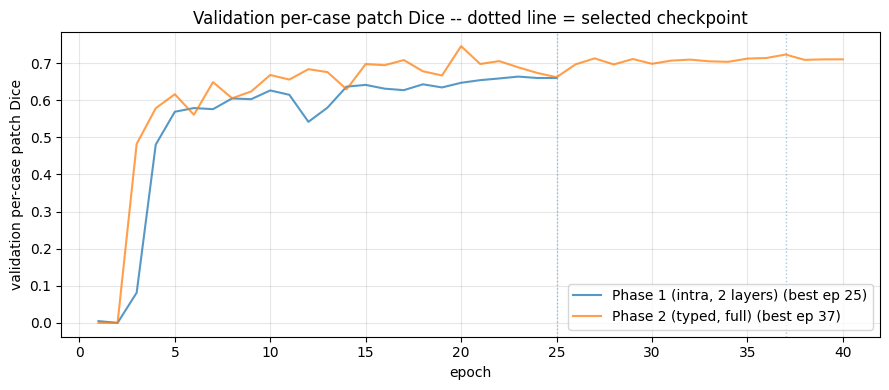

In [14]:

print("Phase 2")
print(f"train graphs {len(train_g)} ({len(TRAIN_IDS)} real + {len(aug_graphs)} augmented) | "
      f"val {len(val_g)} | test {len(test_g)}")

main_model, main_info = train_segmentation(train_g, val_g, DEVICE,
                                          edge_mode="typed", seed=42)

main_patch = per_case_metrics(main_model, test_g, DEVICE)
main_pixel = pixel_metrics(main_model, test_g, patients, DEVICE)
main_val_patch = per_case_metrics(main_model, val_g, DEVICE)

print(f"\nbest smoothed val dice : {main_info['best_smoothed_val_dice']:.4f} "
      f"(epoch {main_info['best_epoch']} of {len(main_info['val_history'])})")
print()
report(main_patch, "Phase 2 test patch Dice")
print()
report(main_pixel, "Phase 2 test pixel Dice", keys=("dice", "precision", "recall"))

print("val vs test")
print(f"val  per-case patch dice : {main_val_patch['dice']['mean']:.4f}")
print(f"test per-case patch dice : {main_patch['dice']['mean']:.4f}")
print(f"gap : {main_val_patch['dice']['mean'] - main_patch['dice']['mean']:+.4f}")

print("Phase 1 vs Phase 2")
print(f"{'metric':<28}{'Phase 1':>12}{'Phase 2':>12}{'delta':>10}")
for _k, _a, _b in (("per-case patch dice", p1_patch["dice"], main_patch["dice"]),
                   ("per-case PIXEL dice", p1_pixel["dice"], main_pixel["dice"])):
    print(f"{_k:<28}{_a['mean']:>12.4f}{_b['mean']:>12.4f}{_b['mean'] - _a['mean']:>+10.4f}")

# paired test over the patients both models scored
_common = sorted(set(p1_pixel["patient_ids"]) & set(main_pixel["patient_ids"]))
_a = np.array([p1_pixel["per_patient_dice"][p1_pixel["patient_ids"].index(p)] for p in _common])
_bb = np.array([main_pixel["per_patient_dice"][main_pixel["patient_ids"].index(p)] for p in _common])
if len(_common) >= 6 and np.any(_a != _bb):
    _w = wilcoxon(_bb, _a)
    print(f"\npaired Wilcoxon over {len(_common)} patients (pixel dice): "
          f"p = {_w.pvalue:.4f}, Phase 2 better on {int((_bb > _a).sum())}/{len(_common)}")
else:
    print(f"\ntoo few paired cases for a signed-rank test (n={len(_common)})")

plot_history([phase1_info, main_info], ["Phase 1 (intra, 2 layers)", "Phase 2 (typed, full)"],
             "Validation per-case patch Dice -- dotted line = selected checkpoint")

RESULTS["phase2_patch_dice"] = main_patch["dice"]
RESULTS["phase2_pixel_dice"] = main_pixel["dice"]
RESULTS["phase2_val_dice"] = main_val_patch["dice"]["mean"]
RESULTS["phase2_best_epoch"] = main_info["best_epoch"]


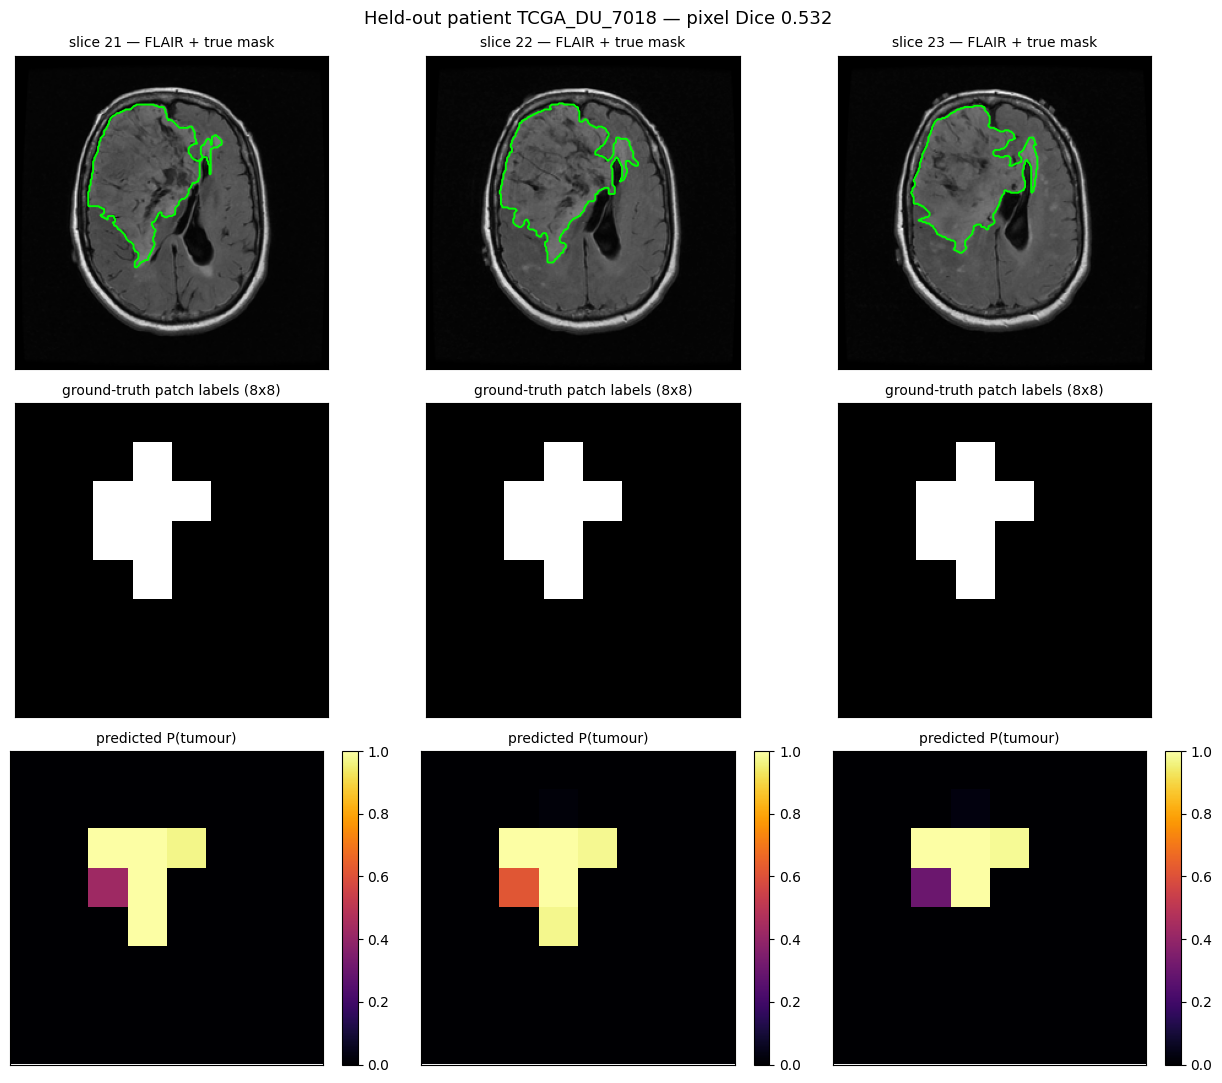

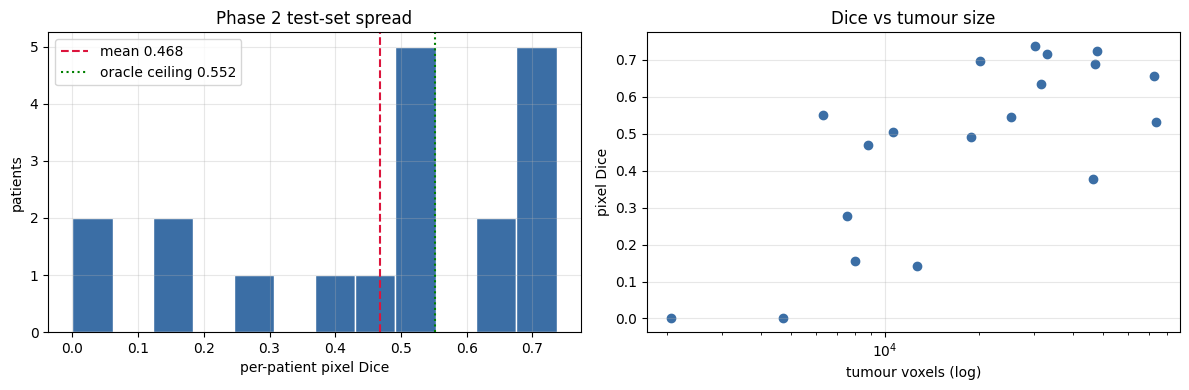

per-patient pixel Dice: min 0.000  median 0.532  max 0.737  std 0.237
patients below 0.30: 5/19
correlation(log tumour volume, pixel Dice) = +0.744


In [15]:
# largest test tumour so there is something to look at
main_model.eval()

_cand = sorted(((patients[g.patient_id].masks.sum(), g.patient_id) for g in test_g
                if g.patient_id in patients), reverse=True)
_pid = _cand[0][1]
_graph = next(g for g in test_g if g.patient_id == _pid)
_pat = patients[_pid]

_d = copy.copy(_graph)
_d.batch = torch.zeros(_graph.num_nodes, dtype=torch.long)
_d = _d.to(DEVICE)
with torch.no_grad():
    _seg, _, _ = main_model(_d)
    _prob = F.softmax(_seg, dim=1)[:, 1].cpu().numpy()

_S = int(_graph.num_slices)
_prob_grid = _prob.reshape(_S, GRID, GRID)
_true_grid = _graph.y.numpy().reshape(_S, GRID, GRID)

# three slices with the most tumour
_order = np.argsort(-_true_grid.sum(axis=(1, 2)))[:3]
_order = sorted(_order.tolist())

fig, axes = plt.subplots(3, len(_order), figsize=(4.2 * len(_order), 11), squeeze=False)
for c, k in enumerate(_order):
    flair = _pat.volume[1, k]
    axes[0, c].imshow(flair, cmap="gray")
    axes[0, c].contour(_pat.masks[k], levels=[0.5], colors="lime", linewidths=1.4)
    axes[0, c].set_title(f"slice {_pat.slice_numbers[k]} — FLAIR + true mask", fontsize=10)

    axes[1, c].imshow(_true_grid[k], cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    axes[1, c].set_title(f"ground-truth patch labels ({GRID}x{GRID})", fontsize=10)

    im = axes[2, c].imshow(_prob_grid[k], cmap="inferno", vmin=0, vmax=1, interpolation="nearest")
    axes[2, c].set_title("predicted P(tumour)", fontsize=10)
    plt.colorbar(im, ax=axes[2, c], fraction=0.046)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"Held-out patient {_pid} — pixel Dice "
             f"{main_pixel['per_patient_dice'][main_pixel['patient_ids'].index(_pid)]:.3f}",
             fontsize=13)
plt.tight_layout(); plt.show()

_pp = np.array(main_pixel["per_patient_dice"])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(_pp, bins=12, color="#3b6ea5", edgecolor="white")
ax[0].axvline(_pp.mean(), color="crimson", ls="--",
              label=f"mean {_pp.mean():.3f}")
ax[0].axvline(ORACLE_MACRO, color="green", ls=":",
              label=f"oracle ceiling {ORACLE_MACRO:.3f}")
ax[0].set_xlabel("per-patient pixel Dice"); ax[0].set_ylabel("patients")
ax[0].set_title("Phase 2 test-set spread"); ax[0].legend(); ax[0].grid(alpha=0.3)

_burden = np.array([patients[p].masks.sum() for p in main_pixel["patient_ids"]])
ax[1].scatter(_burden, _pp, c="#3b6ea5")
ax[1].set_xscale("log")
ax[1].set_xlabel("tumour voxels (log)"); ax[1].set_ylabel("pixel Dice")
ax[1].set_title("Dice vs tumour size")
ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"per-patient pixel Dice: min {_pp.min():.3f}  median {np.median(_pp):.3f}  "
      f"max {_pp.max():.3f}  std {_pp.std():.3f}")
print(f"patients below 0.30: {int((_pp < 0.30).sum())}/{len(_pp)}")
if len(_pp) > 3:
    _r = np.corrcoef(np.log(_burden + 1), _pp)[0, 1]
    print(f"correlation(log tumour volume, pixel Dice) = {_r:+.3f}")


## 10. Graph ablation

Four edge modes, same data and budget: none, intra, shared, typed. 5-fold CV, every patient held out once, no extra copies. Headline is typed vs none. Five Wilcoxon tests; Bonferroni bar is p < 0.01. `typed` has a few extra weights — those are the through-plane filters. The next cell is the per-patient difference, not just the mean.


In [16]:
from sklearn.model_selection import StratifiedKFold

ABLATION_CONFIGS = [
    ("D  no message passing (MLP)", "none"),
    ("C  intra-slice only", "intra"),
    ("B  shared conv over union", "shared"),
    ("A  typed intra + inter", "typed"),
]

ABL_CV_FOLDS = 5
ABL_CV_AUG = 0     # no extra copies; this comparison is about the graph

def ablation_cv(configs=ABLATION_CONFIGS, n_folds=ABL_CV_FOLDS, epochs=None,
                seed=0, aug_copies=ABL_CV_AUG, verbose=True):
    """Every patient held out exactly once; all arms matched within a fold."""
    epochs = CFG["abl_epochs"] if epochs is None else epochs
    all_ids = sorted(graphs)

    # stratify folds by tumour burden so no fold is all-easy or all-hard
    burden = np.array([patients[p].masks.sum() for p in all_ids])
    strat = pd.qcut(burden, 3, labels=False)

    out = {m: {"label": lab, "per_patient": {}, "fold_means": [], "gates": []}
           for lab, m in configs}

    for k, (tr_i, te_i) in enumerate(
            StratifiedKFold(n_folds, shuffle=True, random_state=seed).split(all_ids, strat), 1):
        tr_ids = [all_ids[i] for i in tr_i]
        te_ids = [all_ids[i] for i in te_i]
        in_tr, in_va = train_test_split(tr_ids, test_size=0.18, random_state=seed)

        aug = (build_augmented_bank(patients, in_tr, aug_copies, seed=seed + k,
                                    verbose=False) if aug_copies else [])
        f_tr, f_va, f_te, _ = assemble(in_tr, in_va, te_ids, extra_train=aug)

        for lab, mode in configs:
            model, _ = train_segmentation(f_tr, f_va, DEVICE, edge_mode=mode,
                                          epochs=epochs, seed=seed + k,
                                          patience=epochs, verbose=False)
            px = pixel_metrics(model, f_te, patients, DEVICE)
            for pid, dv in zip(px["patient_ids"], px["per_patient_dice"]):
                out[mode]["per_patient"][pid] = dv
            out[mode]["fold_means"].append(px["dice"]["mean"])
            if mode == "typed":
                out[mode]["gates"].append([float(b.gate) for b in model.blocks])
            if verbose:
                print(f"  fold {k}/{n_folds}  {lab:<30} pixel {px['dice']['mean']:.4f}",
                      flush=True)
    return out

print(f"ablation {ABL_CV_FOLDS}-fold CV, {len(graphs)} patients")
print(f"epochs {CFG['abl_epochs']} | {len(ABLATION_CONFIGS)} arms x {ABL_CV_FOLDS} folds = "
      f"{len(ABLATION_CONFIGS) * ABL_CV_FOLDS} training runs")

ablation = ablation_cv()

for _m in ablation:
    ablation[_m]["all_patients"] = np.array(list(ablation[_m]["per_patient"].values()))
    ablation[_m]["pixel"] = np.array(ablation[_m]["fold_means"])

print("ablation results")
print(f"{'config':<32}{'n':>5}{'mean':>10}{'median':>9}{'fold SD':>10}{'vs prev':>10}")
print("-" * 78)
_prev = None
for _, mode in ABLATION_CONFIGS:
    a = ablation[mode]
    v = a["all_patients"]
    _delta = "" if _prev is None else f"{v.mean() - _prev:+.4f}"
    print(f"{a['label']:<32}{v.size:>5}{v.mean():>10.4f}{np.median(v):>9.4f}"
          f"{a['pixel'].std(ddof=1):>10.4f}{_delta:>10}")
    _prev = v.mean()
print(f"{'oracle ceiling (perfect patches)':<32}{'':>5}{ORACLE_MACRO:>10.4f}")

print(f"paired Wilcoxon, n ~ {len(graphs)}")

def paired(mode_a, mode_b):
    a, b = ablation[mode_a]["per_patient"], ablation[mode_b]["per_patient"]
    common = sorted(set(a) & set(b))
    va = np.array([a[p] for p in common])
    vb = np.array([b[p] for p in common])
    if len(common) < 6 or np.all(va == vb):
        return None
    w = wilcoxon(vb, va)
    return dict(n=len(common), mean_delta=float((vb - va).mean()),
                wins=int((vb > va).sum()), p=float(w.pvalue))

_TESTS = (("none", "intra",  "does in-plane message passing help?"),
          ("intra", "shared", "do inter-slice edges help?"),
          ("shared", "typed",  "do typed weights help?"),
          ("intra", "typed",  "full 3D contribution"),
          ("none", "typed",  "HEADLINE: does the graph help at all?"))
for _a, _b, _q in _TESTS:
    r = paired(_a, _b)
    if r is None:
        print(f"{_b:>7} vs {_a:<7} -- too few paired cases")
        continue
    _sig = "SIGNIFICANT" if r["p"] < 0.05 else "not significant"
    print(f"{_b:>7} vs {_a:<7} | delta {r['mean_delta']:+.4f} | "
          f"better on {r['wins']}/{r['n']} | p = {r['p']:.4f}  ({_sig})   {_q}")

print(f"\n{len(_TESTS)} comparisons were run; Bonferroni threshold at alpha=0.05 is "
      f"p < {0.05 / len(_TESTS):.4f}.")

RESULTS["ablation"] = {m: {"pixel_mean": float(ablation[m]["all_patients"].mean()),
                           "pixel_sd": float(ablation[m]["pixel"].std(ddof=1)),
                           "n_patients": int(ablation[m]["all_patients"].size)}
                       for _, m in ABLATION_CONFIGS}
RESULTS["ablation_design"] = f"{ABL_CV_FOLDS}-fold CV over {len(graphs)} patients"
RESULTS["ablation_typed_vs_intra"] = paired("intra", "typed")
RESULTS["ablation_typed_vs_none"] = paired("none", "typed")


ablation 5-fold CV, 110 patients
epochs 25 | 4 arms x 5 folds = 20 training runs
  fold 1/5  D  no message passing (MLP)    pixel 0.4248
  fold 1/5  C  intra-slice only            pixel 0.4383
  fold 1/5  B  shared conv over union      pixel 0.4442
  fold 1/5  A  typed intra + inter         pixel 0.4416
  fold 2/5  D  no message passing (MLP)    pixel 0.4695
  fold 2/5  C  intra-slice only            pixel 0.4735
  fold 2/5  B  shared conv over union      pixel 0.4803
  fold 2/5  A  typed intra + inter         pixel 0.4931
  fold 3/5  D  no message passing (MLP)    pixel 0.4715
  fold 3/5  C  intra-slice only            pixel 0.4875
  fold 3/5  B  shared conv over union      pixel 0.4972
  fold 3/5  A  typed intra + inter         pixel 0.4922
  fold 4/5  D  no message passing (MLP)    pixel 0.4362
  fold 4/5  C  intra-slice only            pixel 0.4152
  fold 4/5  B  shared conv over union      pixel 0.4191
  fold 4/5  A  typed intra + inter         pixel 0.4560
  fold 5/5  D  no messa

difference distribution -- typed vs none  (HEADLINE)  (n = 110)
mean +0.0197   median +0.0035   IQR [-0.0050, +0.0408]
min -0.4248   max +0.4982   std 0.1199
typed better on 58/110   worse on 36/110   ties 16
corr(log tumour voxels, delta) = +0.090

sensitivity -- drop 3 patients with the largest positive delta:
   dropped: TCGA_HT_A616, TCGA_CS_6668, TCGA_DU_8163   deltas [0.498, 0.481, 0.331]
   remaining mean +0.0080   better on 55/107
   Wilcoxon after drop: p = 0.0068


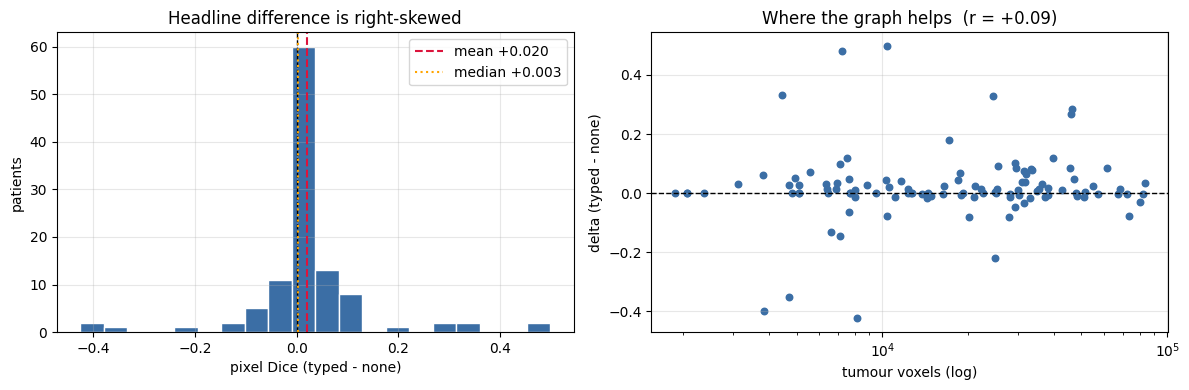

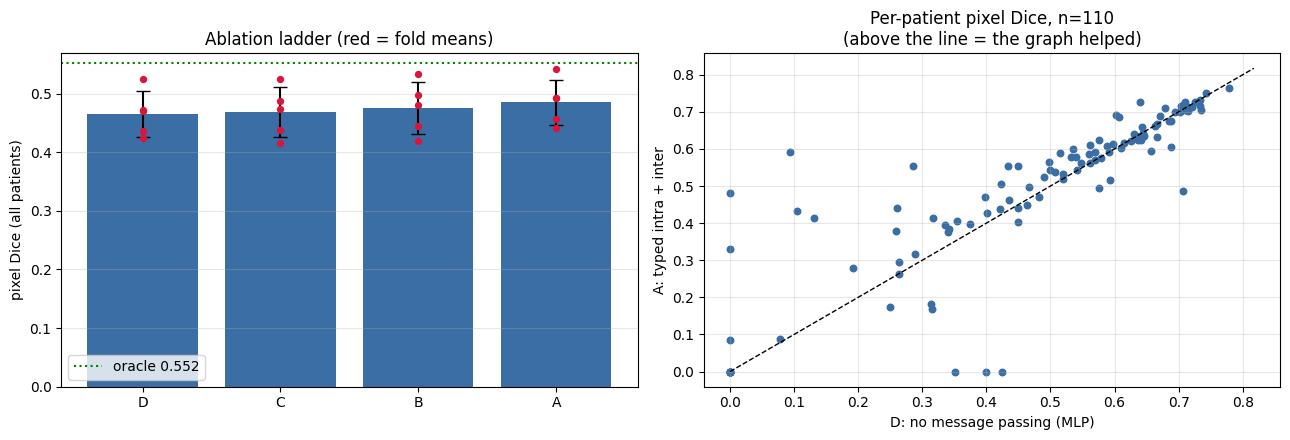

In [17]:
def difference_report(mode_a, mode_b, label):
    """How the graph helps or hurts each patient, not just the average."""
    a, b = ablation[mode_a]["per_patient"], ablation[mode_b]["per_patient"]
    common = sorted(set(a) & set(b))
    va = np.array([a[p] for p in common])
    vb = np.array([b[p] for p in common])
    d = vb - va
    burden = np.array([float(patients[p].masks.sum()) for p in common])
    q25, q50, q75 = np.percentile(d, [25, 50, 75])
    r_vol = float(np.corrcoef(np.log(burden + 1.0), d)[0, 1])

    print(f"difference distribution -- {label}  (n = {len(common)})")
    print(f"mean {d.mean():+.4f}   median {q50:+.4f}   IQR [{q25:+.4f}, {q75:+.4f}]")
    print(f"min {d.min():+.4f}   max {d.max():+.4f}   std {d.std(ddof=1):.4f}")
    print(f"{mode_b} better on {int((d > 0).sum())}/{len(d)}   worse on "
          f"{int((d < 0).sum())}/{len(d)}   ties {int((d == 0).sum())}")
    print(f"corr(log tumour voxels, delta) = {r_vol:+.3f}")
    
    # does the p-value survive dropping the 3 largest positive deltas?
    drop = np.argsort(-d)[:3]
    keep = np.ones(len(d), dtype=bool)
    keep[drop] = False
    print("\nsensitivity -- drop 3 patients with the largest positive delta:")
    print("   dropped:", ", ".join(common[i] for i in drop),
          "  deltas", [round(float(d[i]), 3) for i in drop])
    dk, vak, vbk = d[keep], va[keep], vb[keep]
    print(f"   remaining mean {dk.mean():+.4f}   better on "
          f"{int((dk > 0).sum())}/{keep.sum()}")
    if keep.sum() >= 6 and np.any(vak != vbk):
        p_drop = float(wilcoxon(vbk, vak).pvalue)
        print(f"   Wilcoxon after drop: p = {p_drop:.4f}")
    else:
        p_drop = float("nan")

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].hist(d, bins=20, color="#3b6ea5", edgecolor="white")
    ax[0].axvline(0, color="k", ls="--", lw=1)
    ax[0].axvline(d.mean(), color="crimson", ls="--",
                  label=f"mean {d.mean():+.3f}")
    ax[0].axvline(q50, color="orange", ls=":", label=f"median {q50:+.3f}")
    ax[0].set_xlabel(f"pixel Dice ({mode_b} - {mode_a})")
    ax[0].set_ylabel("patients")
    ax[0].set_title("Headline difference is right-skewed")
    ax[0].legend(); ax[0].grid(alpha=0.3)

    ax[1].scatter(burden, d, c="#3b6ea5", s=22)
    ax[1].axhline(0, color="k", ls="--", lw=1)
    ax[1].set_xscale("log")
    ax[1].set_xlabel("tumour voxels (log)")
    ax[1].set_ylabel(f"delta ({mode_b} - {mode_a})")
    ax[1].set_title(f"Where the graph helps  (r = {r_vol:+.2f})")
    ax[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()

    return dict(n=len(common), mean=float(d.mean()), median=float(q50),
                q25=float(q25), q75=float(q75), r_volume=r_vol,
                n_better=int((d > 0).sum()), n_worse=int((d < 0).sum()),
                p_after_drop3=p_drop)

_diff = difference_report("none", "typed", "typed vs none  (HEADLINE)")
RESULTS["ablation_typed_vs_none_distribution"] = _diff

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for i, (_, m) in enumerate(ABLATION_CONFIGS):
    v = ablation[m]["all_patients"]
    ax[0].bar(i, v.mean(), yerr=ablation[m]["pixel"].std(ddof=1),
              color="#3b6ea5", capsize=5)
    ax[0].scatter([i] * ablation[m]["pixel"].size, ablation[m]["pixel"],
                  color="crimson", zorder=3, s=18)
ax[0].axhline(ORACLE_MACRO, color="green", ls=":", label=f"oracle {ORACLE_MACRO:.3f}")
ax[0].set_xticks(range(len(ABLATION_CONFIGS)))
ax[0].set_xticklabels([m[0][:1] for m in ABLATION_CONFIGS])
ax[0].set_ylabel("pixel Dice (all patients)")
ax[0].set_title("Ablation ladder (red = fold means)")
ax[0].legend(); ax[0].grid(alpha=0.3, axis="y")

_pa, _pb = ablation["none"]["per_patient"], ablation["typed"]["per_patient"]
_c = sorted(set(_pa) & set(_pb))
ax[1].scatter([_pa[p] for p in _c], [_pb[p] for p in _c], color="#3b6ea5", s=22)
_lim = [0, max(max(_pa.values()), max(_pb.values())) * 1.05]
ax[1].plot(_lim, _lim, "k--", lw=1)
ax[1].set_xlabel("D: no message passing (MLP)")
ax[1].set_ylabel("A: typed intra + inter")
ax[1].set_title(f"Per-patient pixel Dice, n={len(_c)}\n(above the line = the graph helped)")
ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()


## 11. Molecular subtype

The segmenter never sees subtype labels. Nested CV retrains it per fold; that is the headline. The pre-declared comparison is gnn+clinical vs clinical. Radiomics use the true mask; the GNN uses its own outline. Accuracy is judged against the majority rate, not 0.5.

We also check whether the embedding just copies histologic grade. Four-class and the 1+2 vs 3+4 grouping are exploratory (frozen model). Single-sequence patients are excluded.


In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, GridSearchCV, RepeatedStratifiedKFold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, roc_auc_score,
                             f1_score, confusion_matrix, classification_report)

RADIOMIC_NAMES = ["burden", "z_extent", "max_xsection", "xsection_sd", "z_mean", "z_sd",
                  "row_mean", "row_sd", "col_mean", "col_sd", "inplane_spread",
                  "perim_to_area", "margin_fill", "z_roughness"]

def radiomic_descriptor(g: Data) -> np.ndarray:
    """
    Hand-built tumor shape / size features from the true mask
    (same spirit as Buda et al. 2019 on this cohort).
    """
    s = int(g.num_slices)
    y = g.y.numpy().reshape(s, GRID, GRID).astype(np.float32)
    frac = g.y_frac.numpy().reshape(s, GRID, GRID)
    per_slice = y.sum(axis=(1, 2))
    tumour = y.sum()
    if tumour == 0:
        return np.zeros(len(RADIOMIC_NAMES), dtype=np.float32)

    zi, ri, ci = np.nonzero(y)
    z = zi / max(s - 1, 1)
    r, c = ri / GRID, ci / GRID
    inv = per_slice > 0

    pad = np.pad(y, ((0, 0), (1, 1), (1, 1)))
    nb = pad[:, :-2, 1:-1] + pad[:, 2:, 1:-1] + pad[:, 1:-1, :-2] + pad[:, 1:-1, 2:]
    perim = float(((y > 0) & (nb < 4)).sum())

    return np.array([
        tumour / y.size,   # burden
        inv.sum() / s, # z-extent
        per_slice.max() / y[0].size, # max cross-section
        per_slice[inv].std() if inv.sum() > 1 else 0.0,    # cross-section variability
        z.mean(), z.std(), r.mean(), r.std(), c.mean(), c.std(),
        float(np.sqrt((r - r.mean()) ** 2 + (c - c.mean()) ** 2).mean()),
        perim / max(tumour, 1.0), # irregularity
        float(frac[y > 0].mean()), # margin sharpness
        float(np.abs(np.diff(per_slice)).mean()), # z-profile roughness
    ], dtype=np.float32)

@torch.no_grad()
def gnn_descriptor(model, g: Data, device) -> np.ndarray:
    """Patient vector after tumor-weighted pooling."""
    model.eval()
    d = copy.copy(g)
    d.batch = torch.zeros(g.num_nodes, dtype=torch.long)
    d = d.to(device)
    return model(d)[2].cpu().numpy().ravel()

def clinical_descriptor(pid: str) -> np.ndarray:
    c = patients[pid].clinical
    return np.array([c.get("age_at_initial_pathologic", np.nan),
                     c.get("gender", np.nan),
                     c.get("neoplasm_histologic_grade", np.nan)], dtype=np.float32)

# primary: gnn+clinical vs clinical
BASE_SETS = ("clinical", "radiomic", "gnn")
FEATURE_SETS = ("clinical", "radiomic", "gnn",
                "gnn+radiomic", "gnn+clinical", "gnn+radiomic+clinical")
PRIMARY_COMPARISON = ("gnn+clinical", "clinical")   # pre-declared

N_PERM = 2000

GNN_PCA_COMPONENTS = None

def reduce_gnn_block(Xtr, Xte, n_components=GNN_PCA_COMPONENTS, seed=0):
    """Leave the patient vector at full size (no extra compression)."""
    return dict(Xtr), dict(Xte), int(Xtr["gnn"].shape[1])

def add_combinations(X):
    """Build the concatenated feature sets."""
    X = dict(X)
    X["gnn+radiomic"] = np.concatenate([X["gnn"], X["radiomic"]], axis=1)
    X["gnn+clinical"] = np.concatenate([X["gnn"], X["clinical"]], axis=1)
    X["gnn+radiomic+clinical"] = np.concatenate(
        [X["gnn"], X["radiomic"], X["clinical"]], axis=1)
    return X

def make_estimator(y_train: np.ndarray):
    """Regularization strength chosen by inner CV; n_jobs=1 because these fits are
    tiny and joblib process spawning would dominate the runtime."""
    inner = int(max(2, min(4, np.bincount(y_train).min())))
    n_cls = len(np.unique(y_train))
    return GridSearchCV(
        Pipeline([("imp", SimpleImputer(strategy="median")),
                  ("sc", StandardScaler()),
                  ("clf", LogisticRegression(max_iter=3000, class_weight="balanced",
                                             random_state=0))]),
        {"clf__C": [0.003, 0.01, 0.03, 0.1, 0.3, 1.0]},
        scoring="roc_auc" if n_cls == 2 else "balanced_accuracy",
        cv=StratifiedKFold(inner, shuffle=True, random_state=0), n_jobs=1)

def score_oof(y, oof, oofp, majority, seed=0):
    """Pooled out-of-fold statistics with the tests that actually control error."""
    n_cls = len(np.unique(y))
    rows = []
    for name in FEATURE_SETS:
        pred = oof[name]
        bal = float(balanced_accuracy_score(y, pred))
        try:
            if n_cls == 2:
                auc = float(roc_auc_score(y, oofp[name][:, 1]))
            else:
                pr = oofp[name] / oofp[name].sum(1, keepdims=True).clip(1e-9)
                auc = float(roc_auc_score(y, pr, multi_class="ovr", average="macro"))
        except ValueError:
            auc = float("nan")           # a fold's training split was missing a class
        rs = np.random.RandomState(seed)
        null = np.array([balanced_accuracy_score(rs.permutation(y), pred)
                         for _ in range(N_PERM)])
        rows.append(dict(
            features=name, n=len(y),
            accuracy=float(accuracy_score(y, pred)), balanced_acc=bal,
            macro_f1=float(f1_score(y, pred, average="macro", zero_division=0)),
            auc=auc,
            binom_p_vs_majority=float(binomtest(int((pred == y).sum()), len(y),
                                                majority, alternative="greater").pvalue),
            perm_p=float((1 + (null >= bal).sum()) / (1 + null.size))))
    return pd.DataFrame(rows)

def eligible(scheme, exclude_single_modality=True):
    elig = [p for p in sorted(graphs)
            if binary_label(patients[p].genomic_cluster, scheme) is not None
            and not (exclude_single_modality and p in SINGLE_MODALITY)]
    y = np.array([binary_label(patients[p].genomic_cluster, scheme) for p in elig])
    return elig, y

def build_descriptors(model, pids, fold_graphs=None):
    """Base descriptors only. Combinations are built by add_combinations."""
    gmap = {g.patient_id: g for g in (fold_graphs or [])}
    return {
        "clinical": np.stack([clinical_descriptor(p) for p in pids]),
        "radiomic": np.stack([radiomic_descriptor(graphs[p]) for p in pids]),
        "gnn": np.stack([gnn_descriptor(model, gmap.get(p, graphs[p]), DEVICE)
                         for p in pids]),
    }

def nested_genomic_cv(scheme=LABEL_SCHEME, n_outer=None, seed=0, epochs=None,
                      aug_copies=0, exclude_single_modality=True, verbose=True):
    """
    Headline path. Retrain the graph model inside every fold so held-out
    patients are unseen even for tumor outlining.
    """
    n_outer = CFG["cv_folds"] if n_outer is None else n_outer
    epochs = CFG["cv_epochs"] if epochs is None else epochs

    elig, y = eligible(scheme, exclude_single_modality)
    pos = {p: i for i, p in enumerate(elig)}
    unl = [p for p in sorted(graphs) if p not in pos]
    n_cls = len(np.unique(y))

    oof = {k: np.zeros(len(y), dtype=int) for k in FEATURE_SETS}
    oofp = {k: np.zeros((len(y), n_cls)) for k in FEATURE_SETS}
    fold_dice, gate_log, dims = [], [], []

    for k, (tr_i, te_i) in enumerate(
            StratifiedKFold(n_outer, shuffle=True, random_state=seed).split(elig, y), 1):
        tr_ids = [elig[i] for i in tr_i]
        te_ids = [elig[i] for i in te_i]
        in_tr, in_va = train_test_split(tr_ids, test_size=0.18, random_state=seed,
                                        stratify=y[tr_i])
        seg_train = sorted(in_tr + unl)          # unlabelled = free segmentation data

        aug = (build_augmented_bank(patients, seg_train, aug_copies,
                                    seed=seed + k, verbose=False) if aug_copies else [])
        f_tr, f_va, f_te, _ = assemble(seg_train, in_va, te_ids, extra_train=aug)

        model, _ = train_segmentation(f_tr, f_va, DEVICE, edge_mode="typed",
                                      epochs=epochs, seed=seed + k,
                                      patience=epochs, verbose=False)
        fold_dice.append(pixel_metrics(model, f_te, patients, DEVICE)["dice"]["mean"])
        gate_log.append([float(b.gate) for b in model.blocks])

        lab_tr = [p for p in seg_train if p in pos]
        Xtr = build_descriptors(model, lab_tr, f_tr)
        Xte = build_descriptors(model, te_ids, f_te)
        Xtr, Xte, kdim = reduce_gnn_block(Xtr, Xte, seed=seed)
        Xtr, Xte = add_combinations(Xtr), add_combinations(Xte)
        dims.append(kdim)
        ytr = np.array([y[pos[p]] for p in lab_tr])

        line = []
        for name in FEATURE_SETS:
            est = make_estimator(ytr).fit(Xtr[name], ytr)
            oof[name][te_i] = est.predict(Xte[name])
            pr = est.predict_proba(Xte[name])
            oofp[name][te_i, :pr.shape[1]] = pr
            line.append(f"{name} {(oof[name][te_i] == y[te_i]).mean():.2f}")
        if verbose:
            print(f"  fold {k}/{n_outer}: n_train {len(lab_tr)} | gnn dim {kdim} | "
                  f"seg dice {fold_dice[-1]:.4f}\n      " + "  ".join(line), flush=True)

    majority = float(np.bincount(y).max() / len(y))
    return dict(table=score_oof(y, oof, oofp, majority, seed), y=y, oof=oof, oofp=oofp,
                pids=elig, majority=majority, fold_dice=fold_dice, gates=gate_log,
                n_classes=n_cls, scheme=scheme, mode="nested", gnn_dim=dims)

def frozen_genomic_cv(model, scheme, n_splits=None, seed=0, verbose=True,
                      exclude_single_modality=True):
    """
    Faster path: reuse one already-trained model. Slightly optimistic for
    outlining (not for subtype labels). Use for secondary schemes only.
    """
    n_splits = CFG["cv_folds"] if n_splits is None else n_splits
    elig, y = eligible(scheme, exclude_single_modality)
    n_cls = len(np.unique(y))

    sc = NodeScaler().fit([graphs[p] for p in TRAIN_IDS])
    scaled = {g.patient_id: g for g in sc.apply([graphs[p] for p in elig])}
    Xbase = build_descriptors(model, elig, list(scaled.values()))

    oof = {k: np.zeros(len(y), dtype=int) for k in FEATURE_SETS}
    oofp = {k: np.zeros((len(y), n_cls)) for k in FEATURE_SETS}
    for k, (tr_i, te_i) in enumerate(
            StratifiedKFold(n_splits, shuffle=True, random_state=seed).split(elig, y), 1):
        Xtr = {n: Xbase[n][tr_i] for n in BASE_SETS}
        Xte = {n: Xbase[n][te_i] for n in BASE_SETS}
        Xtr, Xte, _ = reduce_gnn_block(Xtr, Xte, seed=seed)
        Xtr, Xte = add_combinations(Xtr), add_combinations(Xte)
        for name in FEATURE_SETS:
            est = make_estimator(y[tr_i]).fit(Xtr[name], y[tr_i])
            oof[name][te_i] = est.predict(Xte[name])
            pr = est.predict_proba(Xte[name])
            oofp[name][te_i, :pr.shape[1]] = pr
        if verbose:
            print(f"  fold {k}/{n_splits}: acc " + "  ".join(
                f"{n} {(oof[n][te_i] == y[te_i]).mean():.2f}" for n in FEATURE_SETS),
                flush=True)

    majority = float(np.bincount(y).max() / len(y))
    return dict(table=score_oof(y, oof, oofp, majority, seed), y=y, oof=oof, oofp=oofp,
                pids=elig, majority=majority, fold_dice=[], gates=[],
                n_classes=n_cls, scheme=scheme, mode="frozen", gnn_dim=[])

def agesex_descriptor(pid: str) -> np.ndarray:
    """Age and sex only (grade left out on purpose)."""
    c = patients[pid].clinical
    return np.array([c.get("age_at_initial_pathologic", np.nan),
                     c.get("gender", np.nan)], dtype=np.float32)

def frozen_binary_cv(model, pids, y, feature_builder, n_splits=None, seed=0,
                     verbose=True, title=""):
    """Predict a binary label from frozen patient vectors."""
    n_splits = CFG["cv_folds"] if n_splits is None else n_splits
    sc = NodeScaler().fit([graphs[p] for p in TRAIN_IDS])
    scaled = {g.patient_id: g for g in sc.apply([graphs[p] for p in pids])}
    Xbase = feature_builder(model, pids, list(scaled.values()))
    names = list(Xbase)
    n_cls = len(np.unique(y))
    oof = {k: np.zeros(len(y), dtype=int) for k in names}
    oofp = {k: np.zeros((len(y), n_cls)) for k in names}
    for k, (tr_i, te_i) in enumerate(
            StratifiedKFold(n_splits, shuffle=True, random_state=seed).split(pids, y), 1):
        for name in names:
            est = make_estimator(y[tr_i]).fit(Xbase[name][tr_i], y[tr_i])
            oof[name][te_i] = est.predict(Xbase[name][te_i])
            pr = est.predict_proba(Xbase[name][te_i])
            oofp[name][te_i, :pr.shape[1]] = pr
        if verbose:
            print(f"  fold {k}/{n_splits}: " + "  ".join(
                f"{n} {(oof[n][te_i] == y[te_i]).mean():.2f}" for n in names),
                flush=True)
    majority = float(np.bincount(y).max() / len(y))
    # score_oof expects FEATURE_SETS keys; score locally instead
    rows = []
    for name in names:
        pred = oof[name]
        bal = float(balanced_accuracy_score(y, pred))
        try:
            auc = float(roc_auc_score(y, oofp[name][:, 1])) if n_cls == 2 else float("nan")
        except ValueError:
            auc = float("nan")
        rs = np.random.RandomState(seed)
        null = np.array([balanced_accuracy_score(rs.permutation(y), pred)
                         for _ in range(N_PERM)])
        rows.append(dict(features=name, n=len(y),
                         accuracy=float(accuracy_score(y, pred)),
                         balanced_acc=bal, auc=auc,
                         perm_p=float((1 + (null >= bal).sum()) / (1 + null.size))))
    return dict(table=pd.DataFrame(rows), y=y, oof=oof, oofp=oofp,
                pids=pids, majority=majority, title=title)

def grade_feature_builder(model, pids, fold_graphs=None):
    gmap = {g.patient_id: g for g in (fold_graphs or [])}
    gnn = np.stack([gnn_descriptor(model, gmap.get(p, graphs[p]), DEVICE) for p in pids])
    rad = np.stack([radiomic_descriptor(graphs[p]) for p in pids])
    agesex = np.stack([agesex_descriptor(p) for p in pids])
    return {
        "agesex": agesex,
        "radiomic": rad,
        "gnn": gnn,
        "gnn+agesex": np.concatenate([gnn, agesex], axis=1),
    }

print("genomic machinery defined")
print(f"  radiomic features    : {len(RADIOMIC_NAMES)}")
print(f"  graph patient vector : {3 * CFG['hidden'] * (CFG['layers'] + 1)} numbers")
print(f"  feature sets         : {len(FEATURE_SETS)} -> {list(FEATURE_SETS)}")
print(f"  primary : {PRIMARY_COMPARISON[0]} vs {PRIMARY_COMPARISON[1]}")
print(f"  permutation draws    : {N_PERM}")
print(f"  nested CV (headline, scheme '{LABEL_SCHEME}'): {CFG['cv_folds']} folds x "
      f"{CFG['cv_epochs']} epochs = {CFG['cv_folds']} GNN retrainings")
print("  secondary schemes: frozen model")


genomic machinery defined
  radiomic features    : 14
  graph patient vector : 768 numbers
  feature sets         : 6 -> ['clinical', 'radiomic', 'gnn', 'gnn+radiomic', 'gnn+clinical', 'gnn+radiomic+clinical']
  primary : gnn+clinical vs clinical
  permutation draws    : 2000
  nested CV (headline, scheme 'c2_vs_rest'): 5 folds x 30 epochs = 5 GNN retrainings
  secondary schemes: frozen model


nested CV (scheme 'c2_vs_rest')
  fold 1/5: n_train 58 | gnn dim 768 | seg dice 0.5786
      clinical 0.78  radiomic 0.61  gnn 0.83  gnn+radiomic 0.83  gnn+clinical 0.83  gnn+radiomic+clinical 0.83
  fold 2/5: n_train 58 | gnn dim 768 | seg dice 0.4706
      clinical 0.50  radiomic 0.61  gnn 0.67  gnn+radiomic 0.61  gnn+clinical 0.67  gnn+radiomic+clinical 0.67
  fold 3/5: n_train 58 | gnn dim 768 | seg dice 0.5640
      clinical 0.61  radiomic 0.44  gnn 0.50  gnn+radiomic 0.50  gnn+clinical 0.50  gnn+radiomic+clinical 0.50
  fold 4/5: n_train 58 | gnn dim 768 | seg dice 0.4868
      clinical 0.78  radiomic 0.44  gnn 0.83  gnn+radiomic 0.83  gnn+clinical 0.89  gnn+radiomic+clinical 0.83
  fold 5/5: n_train 59 | gnn dim 768 | seg dice 0.5089
      clinical 0.59  radiomic 0.65  gnn 0.65  gnn+radiomic 0.65  gnn+clinical 0.65  gnn+radiomic+clinical 0.65

mean per-fold tumor-outline pixel Dice 0.5218

n = 89 patients | majority-class rate = 0.6966
             features  n  accuracy  balance

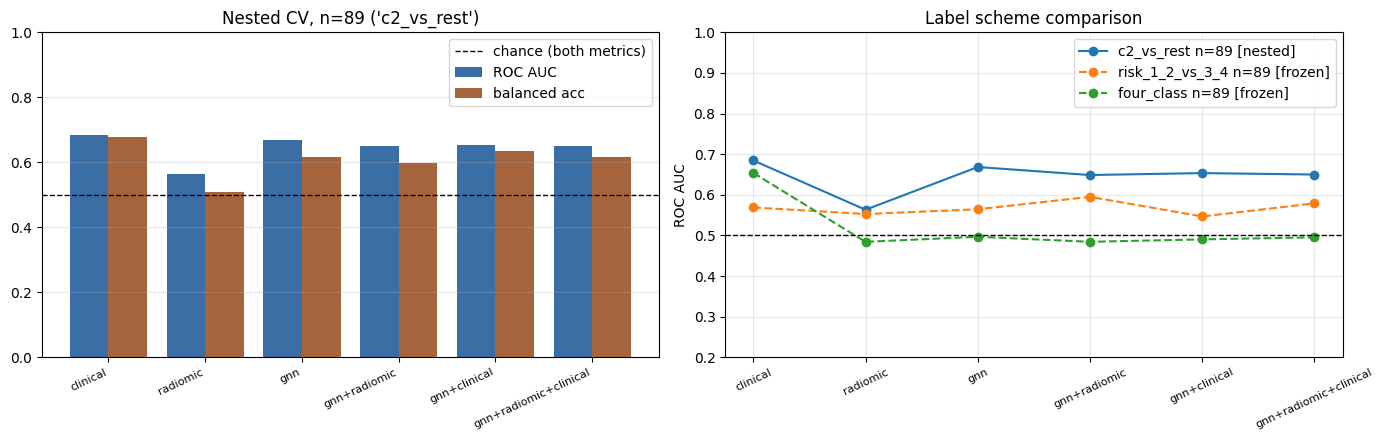

does the GNN embedding recover grade?
frozen embeddings
target: recorded grade == 2  (n = 104, positive rate 0.538)
grade counts among eligible: Counter({np.int64(1): 56, np.int64(0): 48})

  fold 1/5: agesex 0.38  radiomic 0.57  gnn 0.48  gnn+agesex 0.48
  fold 2/5: agesex 0.48  radiomic 0.29  gnn 0.29  gnn+agesex 0.33
  fold 3/5: agesex 0.33  radiomic 0.43  gnn 0.57  gnn+agesex 0.57
  fold 4/5: agesex 0.62  radiomic 0.52  gnn 0.57  gnn+agesex 0.57
  fold 5/5: agesex 0.40  radiomic 0.50  gnn 0.45  gnn+agesex 0.40

n = 104 | majority = 0.5385

  features   n  accuracy  balanced_acc    auc  perm_p
    agesex 104    0.4423        0.4420 0.4364  0.9090
  radiomic 104    0.4615        0.4628 0.4914  0.8356
       gnn 104    0.4712        0.4688 0.5219  0.8021
gnn+agesex 104    0.4712        0.4688 0.5208  0.8076

GNN AUC for GRADE          : 0.5219  (perm p 0.8021)
age+sex AUC for GRADE      : 0.4364
embedding does not recover grade
within-grade subtype AUC (c2_vs_rest)
stratum            

In [20]:

print(f"nested CV (scheme '{LABEL_SCHEME}')")
gen_main = nested_genomic_cv(scheme=LABEL_SCHEME)
print(f"\nmean per-fold tumor-outline pixel Dice "
      f"{np.mean(gen_main['fold_dice']):.4f}")

_tbl = gen_main["table"].copy()
print(f"\nn = {len(gen_main['y'])} patients | majority-class rate = {gen_main['majority']:.4f}")
print(_tbl.round(4).to_string(index=False))

_r = _tbl.set_index("features")
_best_row = _tbl.sort_values("auc", ascending=False).iloc[0]
_gain_clin = _r.loc["gnn+clinical", "auc"] - _r.loc["clinical", "auc"]
_gain_shape = _r.loc["gnn+radiomic", "auc"] - _r.loc["radiomic", "auc"]

print("gnn+clinical vs clinical")
print(f"primary: {PRIMARY_COMPARISON[0]} vs {PRIMARY_COMPARISON[1]}")
for _n in ("clinical", "radiomic", "gnn", "gnn+radiomic", "gnn+clinical",
           "gnn+radiomic+clinical"):
    print(f"   {_n:<24} AUC {_r.loc[_n, 'auc']:.4f}   bal.acc {_r.loc[_n, 'balanced_acc']:.4f}"
          f"   perm p {_r.loc[_n, 'perm_p']:.4f}")
print(f"\nbest feature set by AUC      : {_best_row['features']} ({_best_row['auc']:.4f})")
print(f"GNN gain over clinical       : {_gain_clin:+.4f} AUC")
print(f"GNN gain over shape          : {_gain_shape:+.4f} AUC")

if _gain_clin > 0.02 and _r.loc["gnn+clinical", "perm_p"] < 0.05:
    print("GNN adds something beyond age/sex/grade")
elif _gain_shape > 0.02 and _r.loc["gnn", "perm_p"] < 0.05:
    print("beats shape, does not beat clinical")
elif _r.loc["clinical", "perm_p"] < 0.05:
    print("clinical carries the signal; imaging does not add at this n")
else:
    print("no feature set separates classes at this n")

_best = _best_row["features"]
_y, _p = gen_main["y"], gen_main["oof"][_best]
print(f"oof confusion ({_best})")
print(pd.DataFrame(confusion_matrix(_y, _p),
                   index=[f"true {i}" for i in range(gen_main['n_classes'])],
                   columns=[f"pred {i}" for i in range(gen_main['n_classes'])]).to_string())
print("\n" + classification_report(_y, _p, zero_division=0, digits=3))

print("secondary schemes (frozen model)")
print("frozen model; mildly optimistic vs nested CV above")

print(f"--- old label scheme 'risk_1_2_vs_3_4' ---")
print("molecular split, not a risk split")
gen_old = frozen_genomic_cv(main_model, "risk_1_2_vs_3_4")
print(f"\nn = {len(gen_old['y'])} | majority = {gen_old['majority']:.4f}\n")
print(gen_old["table"].round(4).to_string(index=False))

# 4-class, exploratory

print("4-class (exploratory)")
_cc = Counter(p.genomic_cluster for p in patients.values() if p.genomic_cluster is not None)
print(f"cluster support: {dict(sorted(_cc.items()))}")
print(f"smallest cluster has {min(_cc.values())} patients -> "
      f"~{min(_cc.values()) / CFG['cv_folds']:.1f} held out per fold.")
gen_4c = frozen_genomic_cv(main_model, "four_class")
print(f"\nn = {len(gen_4c['y'])} | majority = {gen_4c['majority']:.4f} | "
      f"chance balanced accuracy = 0.25\n")
print(gen_4c["table"].round(4).to_string(index=False))
_b4 = gen_4c["table"].sort_values("balanced_acc", ascending=False).iloc[0]["features"]
print(f"\nconfusion matrix ('{_b4}'):")
print(pd.DataFrame(confusion_matrix(gen_4c["y"], gen_4c["oof"][_b4]),
                   index=[f"true c{i + 1}" for i in range(4)],
                   columns=[f"pred c{i + 1}" for i in range(4)]).to_string())

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
_names = list(_tbl["features"])
_x = np.arange(len(_names))
ax[0].bar(_x - 0.2, _tbl["auc"], 0.4, label="ROC AUC", color="#3b6ea5")
ax[0].bar(_x + 0.2, _tbl["balanced_acc"], 0.4, label="balanced acc", color="#a5643b")
ax[0].axhline(0.5, color="k", ls="--", lw=1, label="chance (both metrics)")
ax[0].set_xticks(_x); ax[0].set_xticklabels(_names, rotation=25, ha="right", fontsize=8)
ax[0].set_ylim(0, 1); ax[0].legend(); ax[0].grid(alpha=0.3, axis="y")
ax[0].set_title(f"Nested CV, n={len(gen_main['y'])} ('{LABEL_SCHEME}')")

for _lab, _res in (("c2_vs_rest", gen_main), ("risk_1_2_vs_3_4", gen_old), ("four_class", gen_4c)):
    _t = _res["table"].set_index("features")
    ax[1].plot(_t.index, _t["auc"], marker="o",
               ls="-" if _res["mode"] == "nested" else "--",
               label=f"{_lab} n={len(_res['y'])} [{_res['mode']}]")
ax[1].axhline(0.5, color="k", ls="--", lw=1)
ax[1].set_ylabel("ROC AUC"); ax[1].set_ylim(0.2, 1.0)
ax[1].tick_params(axis="x", rotation=25, labelsize=8)
ax[1].legend(); ax[1].grid(alpha=0.3); ax[1].set_title("Label scheme comparison")
plt.tight_layout(); plt.show()

# does the embedding just copy grade?

print("does the GNN embedding recover grade?")
print("frozen embeddings")

_grade_pids = [p for p in sorted(graphs)
               if not np.isnan(patients[p].clinical.get("neoplasm_histologic_grade", np.nan))
               and p not in SINGLE_MODALITY]
_grade_y = np.array([int(patients[p].clinical["neoplasm_histologic_grade"] == 2.0)
                     for p in _grade_pids])
print(f"target: recorded grade == 2  (n = {len(_grade_y)}, "
      f"positive rate {_grade_y.mean():.3f})")
print(f"grade counts among eligible: {Counter(_grade_y)}\n")
gen_grade = frozen_binary_cv(main_model, _grade_pids, _grade_y,
                             grade_feature_builder, title="grade")
print(f"\nn = {len(gen_grade['y'])} | majority = {gen_grade['majority']:.4f}\n")
print(gen_grade["table"].round(4).to_string(index=False))
_gt = gen_grade["table"].set_index("features")
print(f"\nGNN AUC for GRADE          : {_gt.loc['gnn', 'auc']:.4f}  "
      f"(perm p {_gt.loc['gnn', 'perm_p']:.4f})")
print(f"age+sex AUC for GRADE      : {_gt.loc['agesex', 'auc']:.4f}")
if _gt.loc["gnn", "auc"] >= 0.70:
    print("embedding is a strong grade predictor")
elif _gt.loc["gnn", "auc"] >= 0.60:
    print("embedding carries some grade signal")
else:
    print("embedding does not recover grade")

# within-grade subtype AUC from the nested-CV out-of-fold scores

print(f"within-grade subtype AUC ({LABEL_SCHEME})")
_gmap = {p: patients[p].clinical.get("neoplasm_histologic_grade", np.nan)
         for p in gen_main["pids"]}
_gr = np.array([_gmap[p] for p in gen_main["pids"]])
_yp = gen_main["y"]
_gnn_s = gen_main["oofp"]["gnn"][:, 1]
_cli_s = gen_main["oofp"]["clinical"][:, 1]
print(f"{'stratum':<16}{'n':>5}{'pos':>5}{'GNN AUC':>10}{'clinical AUC':>14}")
_within = {}
for _gv in sorted({g for g in _gr if not np.isnan(g)}):
    m = _gr == _gv
    if m.sum() < 8 or len(np.unique(_yp[m])) < 2:
        print(f"grade {_gv:<10}{int(m.sum()):>5}  too small / one class")
        continue
    try:
        ag = float(roc_auc_score(_yp[m], _gnn_s[m]))
    except ValueError:
        ag = float("nan")
    try:
        ac = float(roc_auc_score(_yp[m], _cli_s[m]))
    except ValueError:
        ac = float("nan")
    _within[float(_gv)] = dict(n=int(m.sum()), pos=int(_yp[m].sum()),
                               gnn_auc=ag, clinical_auc=ac)
    print(f"grade {_gv:<10}{int(m.sum()):>5}{int(_yp[m].sum()):>5}"
          f"{ag:>10.4f}{ac:>14.4f}")

RESULTS["genomic_main"] = _tbl.to_dict("records")
RESULTS["genomic_scheme"] = LABEL_SCHEME
RESULTS["genomic_n"] = int(len(gen_main["y"]))
RESULTS["genomic_majority"] = gen_main["majority"]
RESULTS["genomic_gnn_gain_auc"] = float(_gain_shape)
RESULTS["genomic_gnn_gain_over_clinical"] = float(_gain_clin)
RESULTS["genomic_best_feature_set"] = str(_best_row["features"])
RESULTS["genomic_primary_comparison"] = list(PRIMARY_COMPARISON)
RESULTS["genomic_gnn_dim"] = gen_main["gnn_dim"]
RESULTS["gnn_predicts_grade"] = gen_grade["table"].to_dict("records")
RESULTS["subtype_auc_within_grade"] = _within


## 12. What the model is using

Gates scale through-plane messages (start at 0.5). Setting them to 0 at test time asks whether *this* model depends on 3D; the ablation is the fair retrain estimate. GNNExplainer and gradient attribution are supporting checks. Last cell reprints one results table.


learned gates
main model : [0.5235, 0.6071, 0.653]   mean |gate| = 0.5945
ablation folds (5 runs) mean per layer: [0.5355, 0.5762, 0.6077]
nested-CV folds (5 runs) mean per layer: [0.5229, 0.5793, 0.6251]
nested-CV folds  SD  per layer: [0.0306, 0.0263, 0.0314]
GNNExplainer (TCGA_DU_7018)
   explainer epoch 37/150  fidelity loss 0.0028
   explainer epoch 74/150  fidelity loss 0.0028
   explainer epoch 111/150  fidelity loss 0.0027
   explainer epoch 148/150  fidelity loss 0.0026

intra-slice edge mask : mean 0.4634  (n = 15,120)
inter-slice edge mask : mean 0.4107  (n = 4,480)
ratio inter/intra     : 0.8863

top 12 features by learned mask weight:
   post_std                 0.6788
   post_mean                0.6744
   post_p10                 0.6249
   pre_kurt                 0.6131
   row                      0.5976
   flair_skew               0.5652
   flair_localcontrast      0.5308
   flair_mean               0.5201
   pre_p10                  0.5189
   post_entropy             0

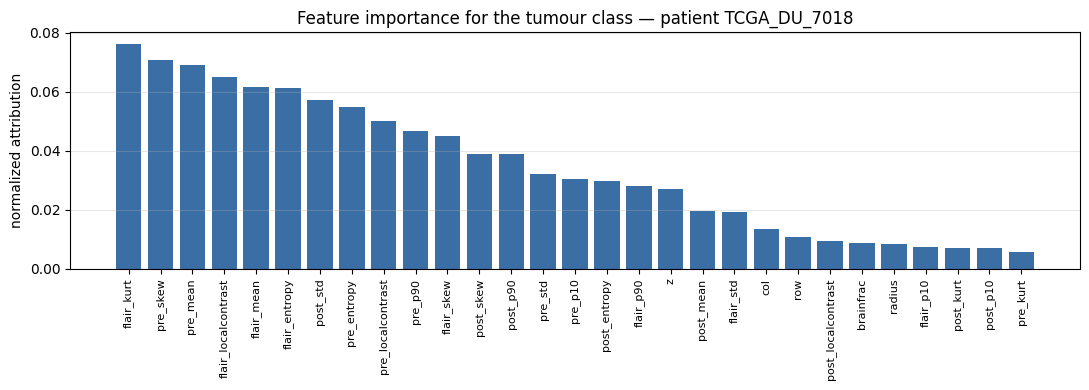

top 8: flair_kurt (0.076), pre_skew (0.071), pre_mean (0.069), flair_localcontrast (0.065), flair_mean (0.062), flair_entropy (0.061), post_std (0.057), pre_entropy (0.055)
new features:
   z                        attribution 0.0272  (rank 18/29)
   flair_localcontrast      attribution 0.0650  (rank 4/29)
   pre_localcontrast        attribution 0.0500  (rank 9/29)
   post_localcontrast       attribution 0.0094  (rank 23/29)
   radius                   attribution 0.0083  (rank 25/29)
3D rendering
saved tumor_3d_TCGA_DU_7018.html
results
preset : laptop  (patch 32, hidden 64, layers 3)
patients / slices : 110 / 3929
invalid inter-slice links : 704 -> 0
positive node rate : 0.8288%
oracle pixel Dice (per-case) : 0.5518  <- ceiling

segmentation
  Phase 1 patch Dice= : 0.6353  [0.5026, 0.7561]
  Phase 1 PIXEL Dice : 0.4168  [0.3009, 0.5219]
  Phase 2 patch Dice : 0.7376  [0.6119, 0.8392]
  Phase 2 PIXEL Dice : 0.4681  [0.3566, 0.5666]
  Phase 2 val patch Dice : 0.7231  (val-test gap -0.0

In [21]:
print("learned gates")
_g_main = [float(b.gate) for b in main_model.blocks]
print(f"main model : {[round(v, 4) for v in _g_main]}   mean |gate| = {np.mean(np.abs(_g_main)):.4f}")
if ablation["typed"]["gates"]:
    _ga = np.array(ablation["typed"]["gates"])
    print(f"ablation folds ({_ga.shape[0]} runs) mean per layer: {_ga.mean(0).round(4).tolist()}")
_gcv = np.array(gen_main["gates"])
print(f"nested-CV folds ({_gcv.shape[0]} runs) mean per layer: {_gcv.mean(0).round(4).tolist()}")
print(f"nested-CV folds  SD  per layer: {_gcv.std(0).round(4).tolist()}")

def gnn_explainer(model, graph, device, epochs=None, lr=0.05,
                  l1=5e-4, ent=1e-3, verbose=True):
    """
    The real GNNExplainer objective: learn soft masks over edges and features that
    maximize fidelity to the model's own prediction under sparsity + entropy
    regularization. Separate masks for intra-slice and inter-slice edges.
    """
    epochs = CFG["explain_epochs"] if epochs is None else epochs
    model.eval()
    for p in model.parameters():
        p.requires_grad_(False)

    d = copy.copy(graph)
    d.batch = torch.zeros(graph.num_nodes, dtype=torch.long)
    d = d.to(device)
    with torch.no_grad():
        target = model(d)[0].argmax(1)

    n_i, n_e = d.edge_index_intra.shape[1], d.edge_index_inter.shape[1]
    m_intra = nn.Parameter(torch.randn(n_i, device=device) * 0.1)
    m_inter = nn.Parameter(torch.randn(max(n_e, 1), device=device) * 0.1)
    m_feat = nn.Parameter(torch.randn(d.x.shape[1], device=device) * 0.1)
    opt = torch.optim.Adam([m_intra, m_inter, m_feat], lr=lr)

    for ep in range(epochs):
        opt.zero_grad()
        wi = torch.sigmoid(m_intra)
        we = torch.sigmoid(m_inter[:n_e]) if n_e > 0 else None
        fm = torch.sigmoid(m_feat)
        seg, _, _ = model(d, x=d.x * fm, w_intra=wi, w_inter=we)
        loss = F.cross_entropy(seg, target)
        for m in ([wi, we, fm] if we is not None else [wi, fm]):
            loss = loss + l1 * m.mean() - ent * (
                m * torch.log(m + 1e-9) + (1 - m) * torch.log(1 - m + 1e-9)).mean()
        loss.backward()
        opt.step()
        if verbose and (ep + 1) % max(epochs // 4, 1) == 0:
            print(f"   explainer epoch {ep + 1}/{epochs}  fidelity loss {float(loss):.4f}")

    for p in model.parameters():
        p.requires_grad_(True)
    return (torch.sigmoid(m_intra).detach().cpu().numpy(),
            torch.sigmoid(m_inter[:n_e]).detach().cpu().numpy() if n_e else np.zeros(0),
            torch.sigmoid(m_feat).detach().cpu().numpy())

print(f"GNNExplainer ({_pid})")
_mi, _me, _mf = gnn_explainer(main_model, _graph, DEVICE)
print(f"\nintra-slice edge mask : mean {_mi.mean():.4f}  (n = {_mi.size:,})")
print(f"inter-slice edge mask : mean {_me.mean():.4f}  (n = {_me.size:,})")
if _me.size:
    print(f"ratio inter/intra     : {_me.mean() / max(_mi.mean(), 1e-9):.4f}")
    
print("\ntop 12 features by learned mask weight:")
_ord = np.argsort(-_mf)
for _i in _ord[:12]:
    print(f"   {FEATURE_NAMES[_i]:<24} {_mf[_i]:.4f}")
print("bottom 5 (least used):")
for _i in _ord[-5:]:
    print(f"   {FEATURE_NAMES[_i]:<24} {_mf[_i]:.4f}")

# gate-zero ≠ ablation: this is whether THIS model uses 3D, not the retrain effect size
print("gate-zero (test time)")
_px_full = pixel_metrics(main_model, test_g, patients, DEVICE)
_saved_gates = [float(b.gate.detach().cpu()) for b in main_model.blocks]
with torch.no_grad():
    for blk in main_model.blocks:
        blk.gate.copy_(torch.zeros_like(blk.gate))
_px_gate0 = pixel_metrics(main_model, test_g, patients, DEVICE)
with torch.no_grad():
    for blk, gval in zip(main_model.blocks, _saved_gates):
        blk.gate.copy_(blk.gate.new_tensor(gval))
print(f"pixel Dice with learned gates        : {_px_full['dice']['mean']:.4f} "
      f"[{_px_full['dice']['lo']:.4f}, {_px_full['dice']['hi']:.4f}]")
print(f"pixel Dice with gates set to 0       : {_px_gate0['dice']['mean']:.4f} "
      f"[{_px_gate0['dice']['lo']:.4f}, {_px_gate0['dice']['hi']:.4f}]")
print(f"gate-zero drop                       : "
      f"{_px_full['dice']['mean'] - _px_gate0['dice']['mean']:+.4f}")
print("this drop is not the 3D effect size; that is typed vs intra in the ablation")
_c = sorted(set(_px_full["patient_ids"]) & set(_px_gate0["patient_ids"]))
if len(_c) >= 6:
    _a = np.array([_px_full["per_patient_dice"][_px_full["patient_ids"].index(p)] for p in _c])
    _b = np.array([_px_gate0["per_patient_dice"][_px_gate0["patient_ids"].index(p)] for p in _c])
    if np.any(_a != _b):
        print(f"paired Wilcoxon over {len(_c)} patients: p = {wilcoxon(_a, _b).pvalue:.4f}")
    else:
        print("gate-zero changed nothing -- this model does not use inter-slice edges")

_retrain = RESULTS.get("ablation_typed_vs_intra") or {}
print("retrain estimate (typed vs intra):")
if _retrain:
    print(f"   delta {_retrain['mean_delta']:+.4f}   p = {_retrain['p']:.4f}   "
          f"better on {_retrain['wins']}/{_retrain['n']}")
else:
    print("   (run ablation first)")

print("gradient attribution")
main_model.eval()
_d = copy.copy(_graph)
_d.batch = torch.zeros(_graph.num_nodes, dtype=torch.long)
_d = _d.to(DEVICE)
_xin = _d.x.clone().requires_grad_(True)
_seg, _, _ = main_model(_d, x=_xin)
_mask = _d.y == 1
if int(_mask.sum()) > 0:
    _seg[_mask, 1].sum().backward()
    _attr = _xin.grad[_mask].abs().mean(0).cpu().numpy()
    _attr = _attr / (_attr.sum() + 1e-12)
    _ordr = np.argsort(-_attr)
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.bar(range(NUM_FEATURES), _attr[_ordr], color="#3b6ea5")
    ax.set_xticks(range(NUM_FEATURES))
    ax.set_xticklabels([FEATURE_NAMES[i] for i in _ordr], rotation=90, fontsize=8)
    ax.set_ylabel("normalized attribution")
    ax.set_title(f"Feature importance for the tumour class — patient {_pid}")
    ax.grid(alpha=0.3, axis="y"); plt.tight_layout(); plt.show()
    print("top 8: " + ", ".join(f"{FEATURE_NAMES[i]} ({_attr[i]:.3f})" for i in _ordr[:8]))
    _znew = [FEATURE_NAMES.index(n) for n in ("z", "flair_localcontrast", "pre_localcontrast",
                                              "post_localcontrast", "radius")]
    print("new features:")
    for _i in _znew:
        print(f"   {FEATURE_NAMES[_i]:<24} attribution {_attr[_i]:.4f}  "
              f"(rank {int(np.where(_ordr == _i)[0][0]) + 1}/{NUM_FEATURES})")

def visualize_tumor_3d(pid, pats, pred_grid=None, fname=None):
    """Slice order is now anatomically correct, so this renders real geometry."""
    from skimage import measure
    from scipy.ndimage import gaussian_filter

    p = pats[pid]
    flair = p.volume[1]
    flair = (flair - flair.min()) / (flair.max() - flair.min() + 1e-8)
    gt = p.masks.astype(np.float32)
    fig = go.Figure()

    for thr, op, sub in ((0.12, 0.008, 7), (0.30, 0.04, 4), (0.55, 0.12, 2)):
        bz, by, bx = np.where(flair > thr)
        fig.add_trace(go.Scatter3d(
            x=bx[::sub], y=by[::sub], z=bz[::sub], mode="markers",
            marker=dict(size=1.8, color=flair[bz[::sub], by[::sub], bx[::sub]],
                        colorscale="Greys", opacity=op, showscale=False),
            hoverinfo="skip", showlegend=False))

    for vol, colour, name in ((gt, "red", "Ground-truth tumour"),
                              (pred_grid, "#00CFFF", "Predicted tumour")):
        if vol is None or vol.max() <= 0:
            continue
        sm = gaussian_filter(vol.astype(np.float32), sigma=1.0)
        try:
            v, f, _, _ = measure.marching_cubes(sm, level=0.3)
            fig.add_trace(go.Mesh3d(x=v[:, 2], y=v[:, 1], z=v[:, 0],
                                    i=f[:, 0], j=f[:, 1], k=f[:, 2],
                                    color=colour, opacity=0.55, name=name))
        except Exception:
            tz, ty, tx = np.where(vol > 0)
            fig.add_trace(go.Scatter3d(x=tx, y=ty, z=tz, mode="markers",
                                       marker=dict(size=4, color=colour), name=name))

    ex, ey, ez = [], [], []
    for i in range(p.num_slices - 1):
        a, b = gt[i], gt[i + 1]
        if a.sum() > 0 and b.sum() > 0:
            y1, x1 = np.where(a > 0)
            y2, x2 = np.where(b > 0)
            ex += [x1.mean(), x2.mean(), None]
            ey += [y1.mean(), y2.mean(), None]
            ez += [i, i + 1, None]
    fig.add_trace(go.Scatter3d(x=ex, y=ey, z=ez, mode="lines",
                               line=dict(color="#00FF88", width=6),
                               name="Inter-slice edges (correct z-order)", hoverinfo="skip"))

    _axis = dict(backgroundcolor="#0A1628", gridcolor="#1B3A6B", color="white",
                 showbackground=True)
    fig.update_layout(
        title=dict(text=f"3D tumour — {pid}<br><sup>red = truth | blue = prediction | "
                        "green = inter-slice edges</sup>",
                   font=dict(size=15, color="white"), x=0.5),
        scene=dict(xaxis=_axis, yaxis=_axis, zaxis=dict(title="slice", **_axis),
                   bgcolor="#0A1628", camera=dict(eye=dict(x=1.8, y=1.8, z=1.0)),
                   aspectmode="data"),
        paper_bgcolor="#0A1628", legend=dict(font=dict(color="white"), bgcolor="#1B3A6B"),
        margin=dict(l=0, r=0, t=80, b=0), height=750)
    fname = fname or f"tumor_3d_{pid}.html"
    fig.write_html(fname)
    print(f"saved {fname}")
    return fig

_pred_vol = np.repeat(np.repeat((_prob_grid > 0.5).astype(np.float32), PATCH, axis=1),
                      PATCH, axis=2)
print("3D rendering")
visualize_tumor_3d(_pid, patients, pred_grid=_pred_vol)

RESULTS["gates_main"] = _g_main
RESULTS["gates_cv_mean"] = _gcv.mean(0).tolist()
RESULTS["explainer_inter_over_intra"] = float(_me.mean() / max(_mi.mean(), 1e-9)) if _me.size else 0.0
RESULTS["occlusion_delta_pixel_dice"] = float(_px_full["dice"]["mean"] - _px_gate0["dice"]["mean"])
RESULTS["occlusion_method"] = "gate-zero (degree-safe)"

print("results")

def _fmt(d):
    if isinstance(d, dict) and "mean" in d:
        return f"{d['mean']:.4f}  [{d['lo']:.4f}, {d['hi']:.4f}]"
    if isinstance(d, float):
        return f"{d:.4f}"
    return str(d)

print(f"preset : {PRESET}  (patch {PATCH}, hidden {CFG['hidden']}, "
      f"layers {CFG['layers']})")
print(f"patients / slices : {RESULTS['n_patients']} / {RESULTS['n_slices']}")
print(f"invalid inter-slice links : {RESULTS['invalid_interslice_links_old']} -> "
      f"{RESULTS['invalid_interslice_links_new']}")
print(f"positive node rate : {RESULTS['positive_node_rate']:.4%}")
print(f"oracle pixel Dice (per-case) : {RESULTS['oracle_pixel_dice_macro']:.4f}  <- ceiling")
print()
print("segmentation")
print(f"  Phase 1 patch Dice= : {_fmt(RESULTS['phase1_patch_dice'])}")
print(f"  Phase 1 PIXEL Dice : {_fmt(RESULTS['phase1_pixel_dice'])}")
print(f"  Phase 2 patch Dice : {_fmt(RESULTS['phase2_patch_dice'])}")
print(f"  Phase 2 PIXEL Dice : {_fmt(RESULTS['phase2_pixel_dice'])}")
print(f"  Phase 2 val patch Dice : {RESULTS['phase2_val_dice']:.4f}  "
      f"(val-test gap "
      f"{RESULTS['phase2_val_dice'] - RESULTS['phase2_patch_dice']['mean']:+.4f})")
print()
print(f"ABLATION ({RESULTS['ablation_design']}; pixel Dice, SD across folds)")
for _, _m in ABLATION_CONFIGS:
    _a = RESULTS["ablation"][_m]
    print(f"  {ablation[_m]['label']:<32}{_a['pixel_mean']:.4f} +/- {_a['pixel_sd']:.4f}")
for _lbl, _key in (("typed vs intra", "ablation_typed_vs_intra"),
                   ("typed vs none ", "ablation_typed_vs_none")):
    _pw = RESULTS.get(_key)
    if _pw:
        print(f"  {_lbl}: delta {_pw['mean_delta']:+.4f}, p = {_pw['p']:.4f}, "
              f"better on {_pw['wins']}/{_pw['n']} patients")
print()
print(f"GENOMICS (nested CV, GNN retrained per fold, scheme '{RESULTS['genomic_scheme']}')")
print(f"  n = {RESULTS['genomic_n']} patients | majority baseline "
      f"{RESULTS['genomic_majority']:.4f}")
print(pd.DataFrame(RESULTS["genomic_main"])[
    ["features", "accuracy", "balanced_acc", "auc", "perm_p"]].round(4).to_string(index=False))
print(f"  best feature set                       : {RESULTS['genomic_best_feature_set']}")
print(f"  incremental AUC from GNN over radiomics: {RESULTS['genomic_gnn_gain_auc']:+.4f}")
print(f"  incremental AUC from GNN over clinical : {RESULTS['genomic_gnn_gain_over_clinical']:+.4f}")
print()
print("INTERPRETABILITY")
print(f"  learned gates (main) : {[round(v, 3) for v in RESULTS['gates_main']]}")
print(f"  learned gates (CV mean) : {[round(v, 3) for v in RESULTS['gates_cv_mean']]}")
print(f"  explainer inter/intra ratio : {RESULTS['explainer_inter_over_intra']:.4f}")
print(f"  occlusion (gate-zero) delta : {RESULTS['occlusion_delta_pixel_dice']:+.4f}")
if "ablation_typed_vs_none_distribution" in RESULTS:
    _dd = RESULTS["ablation_typed_vs_none_distribution"]
    print(f"  typed-vs-none median delta : {_dd['median']:+.4f}  "
          f"IQR [{_dd['q25']:+.4f}, {_dd['q75']:+.4f}]  "
          f"p after drop-3 {_dd['p_after_drop3']:.4f}")
if "gnn_predicts_grade" in RESULTS:
    _gr = pd.DataFrame(RESULTS["gnn_predicts_grade"]).set_index("features")
    print(f"  GNN AUC for GRADE : {_gr.loc['gnn', 'auc']:.4f}  "
          f"(perm p {_gr.loc['gnn', 'perm_p']:.4f})")

with open("results_summary.json", "w") as fh:
    json.dump(RESULTS, fh, indent=2, default=str)
print("\nsaved results_summary.json")
